# Análise do Desempenho Olímpico e Características Socioeconômicas

**Grupo:** Erick Souza Alberti, Felipe Augusto da Silva Cruz e Guilherme Henrique Pereira da Cunha

## Introdução

Os Jogos Olímpicos são o maior evento esportivo do mundo e possuem grande relevância esportiva, sociocultural e de projeção internacional para os países participantes. O desempenho de cada país costuma ser resumido pelo número absoluto de medalhas, uma medida que pode dificultar comparações entre nações com populações, economias e estruturas esportivas muito diferentes.

Nesse sentido, sendo os Jogos Olímpicos esse evento que, inevitavelmente envolve muito mais que o próprio esporte, torna-se importante pensar em como fatores externos, em especial socioeconômicos estão associados ou correlacionados com o desempenho olímpico dos países. A análise se concentra nos **Jogos Olímpicos de Verão**. Portanto, a motivação desse projeto é evidenciar essa discussão com base em dados e visualizações, evidenciando possíveis padrões e correlações de forma clara e verificável.

Como as fontes possuem coberturas temporais diferentes, serão utilizados diferentes recortes. Nas perguntas 1 e 2, que dependem apenas dos dados olímpicos, serão consideradas todas as edições de Verão disponíveis, de **1896 a 2024**. Já nas perguntas que envolvem indicadores do World Bank, serão consideradas as edições de Verão entre **1960 e 2024**, período em que há sobreposição entre os dados olímpicos e os indicadores socioeconômicos utilizados. A pergunta 6 utiliza especificamente 2024 e a pergunta 8 utiliza 2016, devido às lacunas na base de atletas das edições mais recentes. 

Sendo assim,  nesse trabalho temos como objetivo investigar possíveis relações entre o desempenho olímpico dos países e suas características socioeconômicas, a saber, população total, Produto Interno Bruto (PIB) e PIB per capita. As fontes cobrem as edições dos Jogos de Verão e de Inverno de 1896 a 2026, mas a análise utiliza apenas os recortes de Verão descritos acima. Ao longo do estudo, o desempenho é medido de formas complementares: o número de medalhas, a participação do país no total de medalhas de cada edição e a participação nas medalhas de cada categoria de prova. Além disso, utilizamos perguntas de  diferentes aspectos para abordar essas relações.

Os resultados indicam concentração das medalhas em um grupo reduzido de delegações e associação positiva com os indicadores socioeconômicos, mais forte para o PIB total. Também mostram diferenças de desempenho entre países com características semelhantes e perfis distintos de conquistas em provas individuais e por equipe. 


**Link do Repositório no GitHub:** https://github.com/felipeascruz/AEDV

## Descrição dos Dados

O trabalho utiliza três fontes: dois arquivos CSV com dados olímpicos e indicadores socioeconômicos obtidos pela API do World Bank.

* **Medal Table:** contém o resultado agregado de cada país em cada edição dos Jogos Olímpicos de Verão e de Inverno, de 1896 a 2026. Cada linha corresponde a um país em uma edição ou subedição, e aparecem apenas países que conquistaram ao menos uma medalha. A base possui 1.929 linhas e 11 colunas. Como as medalhas de esportes coletivos são contabilizadas uma única vez, esta tabela será utilizada como fonte principal para o total agregado de medalhas. Em 1956, a subedição equestre de Estocolmo aparece separadamente da edição de Melbourne; por isso, os registros serão agregados por **ano e NOC** antes das análises.

* **Olympic Athletes:** contém 315.094 registros de participação de atletas, com 16 colunas. Cada linha representa um atleta em um evento, de modo que um mesmo atleta pode aparecer diversas vezes. Esta base será usada principalmente para identificar **os participantes identificáveis em cada edição**, inclusive aqueles que conquistaram zero medalhas.

* **World Bank (API):** fornece indicadores anuais por país. Serão utilizados população total, PIB em dólares correntes e PIB per capita em dólares correntes. O arquivo coletado possui dados entre 1960 e 2025; como a última edição de Verão disponível é 2024, as análises socioeconômicas utilizarão as edições entre **1960 e 2024**.

### Combinação das bases

A unidade principal de análise será **delegação/categoria olímpica × edição**. Primeiro, a lista de participantes será obtida da união dos códigos por edição da base de atletas e do quadro de medalhas, preservando também a categoria de equipes mistas (MIX). Em seguida, o quadro de medalhas será agregado por `year` e `noc` e combinado à lista de participantes com uma junção à esquerda. Países participantes que não aparecem no quadro de medalhas receberão valor zero para ouro, prata, bronze e total, evitando que países sem medalhas sejam excluídos das análises.

Os códigos do World Bank seguem majoritariamente o padrão ISO, enquanto os dados olímpicos utilizam códigos NOC. Será feita uma padronização explícita dos identificadores antes da junção por `year + noc`. Casos históricos ou delegações sem correspondência socioeconômica defensável serão mantidos como dados ausentes, em vez de receberem uma correspondência arbitrária. Os valores ausentes de população, PIB e PIB per capita também **não serão removidos globalmente**: cada pergunta utilizará apenas as observações que possuírem os indicadores necessários para aquela análise.

A limpeza é aplicada antes de todas as perguntas: LIB e LBN são unificados em LBN; registros sem NOC e o registro inconsistente de ROC em 2024 são excluídos. A categoria MIX é mantida separadamente, sem atribuição de suas medalhas a países. Nos resumos históricos, “países” inclui as delegações identificadas pelos códigos da fonte; MIX é uma categoria agregada, não um país. O recorte histórico mantém 1906, conforme a fonte. As junções são verificadas para preservar os totais de medalhas por edição e por metal.


In [1]:
# Coleta dos indicadores socioeconômicos do World Bank
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# Códigos oficiais das variáveis de interesse:
# SP.POP.TOTL: População total
# NY.GDP.MKTP.CD: PIB (US$ correntes)
# NY.GDP.PCAP.CD: PIB per capita (US$ correntes)
indicadores_wb = {
    'SP.POP.TOTL': 'population',
    'NY.GDP.MKTP.CD': 'gdp',
    'NY.GDP.PCAP.CD': 'gdp_per_capita'
}

# Se o CSV já estiver disponível, reutiliza o arquivo. Isso evita uma chamada
# desnecessária à API e torna a execução reproduzível mesmo sem internet.
if not Path('world_bank.csv').exists():
    import wbgapi as wb

    df_world_bank = wb.data.DataFrame(
        indicadores_wb.keys(),
        time=range(1960, 2026),
        labels=True,
        numericTimeKeys=True
    ).reset_index()

    df_world_bank.to_csv('world_bank.csv', index=False)

In [2]:
# Célula para importação de bibliotecas e leitura inicial dos dados

df_medalhas = pd.read_csv('medal_table.csv')
df_atletas = pd.read_csv('olympic_athletes.csv')
df_world_bank = pd.read_csv('world_bank.csv')

# Transforma as colunas de anos em uma única coluna 'year'
df_world_bank = df_world_bank.melt(
    id_vars=['economy', 'series', 'Country', 'Series'],
    var_name='year',
    value_name='valor'
)

# Pivota a tabela para que População, PIB e PIB per capita ganhem suas próprias colunas
df_world_bank = df_world_bank.pivot_table(
    index=['economy', 'Country', 'year'],
    columns='series',
    values='valor'
).reset_index()

df_world_bank['year'] = df_world_bank['year'].astype(int)

# Renomeia as colunas do World Bank para facilitar a junção com os dados olímpicos
df_world_bank = df_world_bank.rename(columns=indicadores_wb)
df_world_bank = df_world_bank.rename(columns={'economy': 'iso', 'Country': 'country'})

# O código CHI do World Bank corresponde a Channel Islands e conflita com o NOC CHI do Chile.
# Channel Islands não compete como um NOC próprio, então esse registro é removido antes da conversão.
df_world_bank = df_world_bank[df_world_bank['iso'] != 'CHI'].copy()

iso_para_noc = {
    'DZA': 'ALG', 'AGO': 'ANG', 'ATG': 'ANT', 'ABW': 'ARU', 'ASM': 'ASA', 'BHS': 'BAH', 'BGD': 'BAN', 'BRB': 'BAR',
    'BMU': 'BER', 'BTN': 'BHU', 'BLZ': 'BIZ', 'BWA': 'BOT', 'BHR': 'BRN', 'BRN': 'BRU', 'BGR': 'BUL', 'BFA': 'BUR',
    'KHM': 'CAM', 'CYM': 'CAY', 'COG': 'CGO', 'TCD': 'CHA', 'CHL': 'CHI', 'CRI': 'CRC', 'HRV': 'CRO', 'DNK': 'DEN',
    'SLV': 'ESA', 'FJI': 'FIJ', 'GMB': 'GAM', 'GNB': 'GBS', 'GNQ': 'GEQ', 'DEU': 'GER', 'GRC': 'GRE', 'GRD': 'GRN',
    'GTM': 'GUA', 'GIN': 'GUI', 'HTI': 'HAI', 'HND': 'HON', 'IDN': 'INA', 'IRN': 'IRI', 'VIR': 'ISV', 'VGB': 'IVB',
    'XKX': 'KOS', 'SAU': 'KSA', 'KWT': 'KUW', 'LVA': 'LAT', 'LBY': 'LBA', 'LSO': 'LES', 'MDG': 'MAD', 'MYS': 'MAS',
    'MWI': 'MAW', 'MNG': 'MGL', 'MCO': 'MON', 'MUS': 'MRI', 'MRT': 'MTN', 'MMR': 'MYA', 'NIC': 'NCA', 'NLD': 'NED',
    'NPL': 'NEP', 'NGA': 'NGR', 'NER': 'NIG', 'OMN': 'OMA', 'PRY': 'PAR', 'PHL': 'PHI', 'PSE': 'PLE', 'PRT': 'POR',
    'PRI': 'PUR', 'ZAF': 'RSA', 'WSM': 'SAM', 'SYC': 'SEY', 'KNA': 'SKN', 'SVN': 'SLO', 'SLB': 'SOL', 'LKA': 'SRI',
    'SDN': 'SUD', 'CHE': 'SUI', 'TZA': 'TAN', 'TON': 'TGA', 'TGO': 'TOG', 'ARE': 'UAE', 'URY': 'URU', 'VUT': 'VAN',
    'VNM': 'VIE', 'VCT': 'VIN', 'ZMB': 'ZAM', 'ZWE': 'ZIM'
}

df_world_bank['noc'] = df_world_bank['iso'].replace(iso_para_noc)

# Identificador único para o Líbano nas três bases e em todos os anos.
df_world_bank['noc'] = df_world_bank['noc'].replace({'LIB': 'LBN'})

# A mesma limpeza é aplicada antes de qualquer análise.
def preparar_base_olimpica(dados):
    dados = dados[(dados['season'] == 'Summer') & dados['year'].between(1896, 2024)].copy()
    # Registro isolado inconsistente de ROC em 2024: não atribuir zero à Rússia.
    dados = dados[~((dados['year'] == 2024) & dados['noc'].isin(['ROC', 'RUS']))].copy()
    dados = dados.dropna(subset=['noc'])
    dados['noc'] = dados['noc'].replace({'LIB': 'LBN', 'ROC': 'RUS', 'OAR': 'RUS'})
    return dados

df_medalhas = preparar_base_olimpica(df_medalhas)
df_atletas = preparar_base_olimpica(df_atletas)

# Em 1956, Melbourne e a subedição equestre de Estocolmo aparecem separadamente.
# Somamos os registros para obter uma única observação país × edição.
df_medalhas_pais_edicao = (
    df_medalhas
    .groupby(['year', 'noc'], as_index=False)
    .agg(
        country=('country', 'first'),
        gold=('gold', 'sum'),
        silver=('silver', 'sum'),
        bronze=('bronze', 'sum'),
        total=('total', 'sum')
    )
)

# União das chaves: preserva também as equipes mistas presentes só no quadro.
# MIX é uma categoria agregada de equipes mistas, não um país.
chaves_atletas = df_atletas[['year', 'noc']].drop_duplicates()
chaves_medalhas = df_medalhas_pais_edicao[['year', 'noc']].drop_duplicates()
so_quadro = chaves_medalhas.merge(chaves_atletas, on=['year', 'noc'], how='left', indicator=True)
so_quadro = so_quadro[so_quadro['_merge'] == 'left_only'].drop(columns='_merge')
assert set(so_quadro['noc']).issubset({'MIX'}), 'Revisar novos NOCs presentes somente no quadro.'
df_participantes = pd.concat([chaves_atletas, chaves_medalhas], ignore_index=True).drop_duplicates()

df_olimpico = df_participantes.merge(
    df_medalhas_pais_edicao,
    on=['year', 'noc'],
    how='left',
    validate='one_to_one'
)

# Ausência no quadro de medalhas significa participação com zero medalhas, não dado ausente.
colunas_medalhas = ['gold', 'silver', 'bronze', 'total']
df_olimpico[colunas_medalhas] = df_olimpico[colunas_medalhas].fillna(0).astype(int)

df_pais_edicao = df_olimpico.merge(
    df_world_bank,
    on=['year', 'noc'],
    how='left',
    suffixes=('_olimpico', '_wb'),
    validate='one_to_one'
)

df_pais_edicao['country'] = (
    df_pais_edicao['country_olimpico']
    .fillna(df_pais_edicao['country_wb'])
    .fillna(df_pais_edicao['noc'])
)

df_olimpico_completo = df_pais_edicao.sort_values(['year', 'noc']).reset_index(drop=True)  # 1896–2024: perguntas apenas olímpicas

df_socioeconomico = df_olimpico_completo[
    df_olimpico_completo['year'].between(1960, 2024)
].copy()  # 1960–2024: perguntas que usam World Bank

# Não removemos NaNs socioeconômicos aqui. Cada pergunta filtra apenas o indicador de que precisa.

display(df_socioeconomico)
# Validação: nenhuma medalha do quadro pode desaparecer na junção.
assert not df_olimpico_completo.duplicated(['year', 'noc']).any()
assert df_olimpico_completo['noc'].notna().all()
assert not df_world_bank.duplicated(['year', 'noc']).any()
for coluna in colunas_medalhas:
    esperado = df_medalhas.groupby('year')[coluna].sum().sort_index()
    observado = df_olimpico_completo.groupby('year')[coluna].sum().sort_index()
    pd.testing.assert_series_equal(esperado, observado, check_dtype=False)
assert (df_olimpico_completo['total'] == df_olimpico_completo[['gold', 'silver', 'bronze']].sum(axis=1)).all()
assert not ((df_olimpico_completo['year'] == 2024) & (df_olimpico_completo['noc'] == 'RUS')).any()
print('Validação: totais por edição e por metal preservados; chaves únicas e identificadas.')
display(so_quadro)


,year,noc,country_olimpico,gold,silver,bronze,total,iso,country_wb,gdp,gdp_per_capita,population,country
549,1960,AFG,NaN,0,0,0,0,AFG,Afghanistan,NaN,NaN,9035043.0,Afghanistan
550,1960,AHO,NaN,0,0,0,0,NaN,NaN,NaN,NaN,NaN,AHO
551,1960,ARG,Argentina,0,1,1,2,ARG,Argentina,1.586547e+10,778.251707,20386045.0,Argentina
552,1960,AUS,Australia,8,8,6,22,AUS,Australia,1.863568e+10,1813.431099,10276477.0,Australia
553,1960,AUT,Austria,1,1,0,2,AUT,Austria,6.624086e+09,939.914815,7047539.0,Austria
...,...,...,...,...,...,...,...,...,...,...,...,...,...
3220,2024,VIE,NaN,0,0,0,0,VNM,Viet Nam,4.763246e+11,4716.659938,100987686.0,Viet Nam
3221,2024,VIN,NaN,0,0,0,0,VCT,St. Vincent and the Grenadines,1.157207e+09,11501.226519,100616.0,St. Vincent and the Grenadines
3222,2024,YEM,NaN,0,0,0,0,YEM,"Yemen, Rep.",NaN,NaN,40583164.0,"Yemen, Rep."
3223,2024,ZAM,Zambia,0,0,1,1,ZMB,Zambia,2.530319e+10,1187.109434,21314956.0,Zambia


Validação: totais por edição e por metal preservados; chaves únicas e identificadas.


,year,noc
8,1896,MIX
24,1900,MIX
36,1904,MIX


### 1. Como o desempenho olímpico dos países, medido pelo número de medalhas conquistadas, varia entre as diferentes edições dos Jogos analisadas?

**Transformação dos Dados**

Como esta pergunta utiliza apenas informações olímpicas, foram consideradas todas as edições dos Jogos de Verão presentes na base, entre 1896 e 2024. Cada observação corresponde a uma delegação/categoria participante em determinada edição, incluindo MIX como categoria agregada de equipes mistas.

Países que participaram de uma edição e não conquistaram medalhas foram mantidos na análise com `total = 0`. Essa distinção é importante, pois zero medalhas representa um resultado observado, enquanto a ausência de uma observação indicaria que o país não participou daquela edição.

Para comparar as edições, foram calculadas medidas descritivas da distribuição do número de medalhas entre os países participantes: quantidade de países participantes, número de países medalhistas, total de medalhas da edição, média, mediana, terceiro quartil e maior número de medalhas obtido por um país.


In [3]:
# Resumo do desempenho dos países por edição
resumo_edicoes = (
    df_olimpico_completo
    .groupby('year')
    .agg(
        participantes=('noc', 'nunique'),
        medalhistas=('total', lambda x: (x > 0).sum()),
        total_medalhas=('total', 'sum'),
        media_medalhas=('total', 'mean'),
        mediana_medalhas=('total', 'median'),
        q3_medalhas=('total', lambda x: x.quantile(0.75)),
        max_medalhas=('total', 'max')
    )
    .reset_index()
)

display(resumo_edicoes)

,year,participantes,medalhistas,total_medalhas,media_medalhas,mediana_medalhas,q3_medalhas,max_medalhas
0,1896,13,11,122,9.384615,6.0,11.00,47
1,1900,32,19,284,8.875000,2.0,6.00,112
2,1904,16,8,280,17.500000,0.5,3.25,248
3,1906,21,18,224,10.666667,7.0,15.00,40
4,1908,22,19,324,14.727273,5.0,12.00,146
5,1912,29,19,317,10.931034,5.0,10.00,65
6,1920,29,22,449,15.482759,3.0,25.00,95
7,1924,45,31,392,8.711111,2.0,10.00,99
8,1928,46,34,356,7.739130,3.0,9.00,56
9,1932,47,28,370,7.872340,1.0,8.00,110


Uma primeira visualização mostra como a quantidade de países participantes e de países que conquistaram ao menos uma medalha evoluiu ao longo das edições:


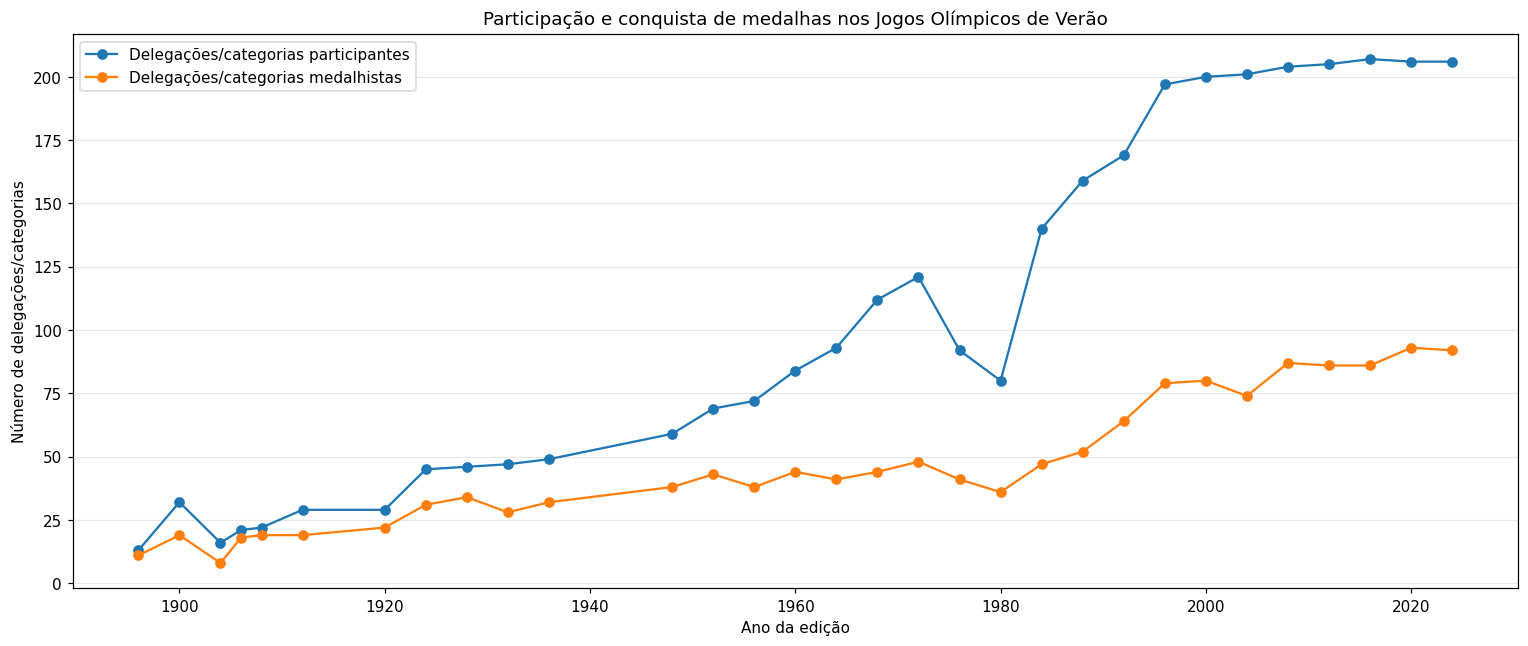

In [4]:

plt.figure(figsize=(14, 6))

plt.plot(
    resumo_edicoes['year'],
    resumo_edicoes['participantes'],
    marker='o',
    label='Delegações/categorias participantes'
)

plt.plot(
    resumo_edicoes['year'],
    resumo_edicoes['medalhistas'],
    marker='o',
    label='Delegações/categorias medalhistas'
)

plt.title('Participação e conquista de medalhas nos Jogos Olímpicos de Verão')
plt.xlabel('Ano da edição')
plt.ylabel('Número de delegações/categorias')
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


Para observar diretamente como o número de medalhas por país varia entre as edições, a análise é complementada com a evolução da média e da mediana:


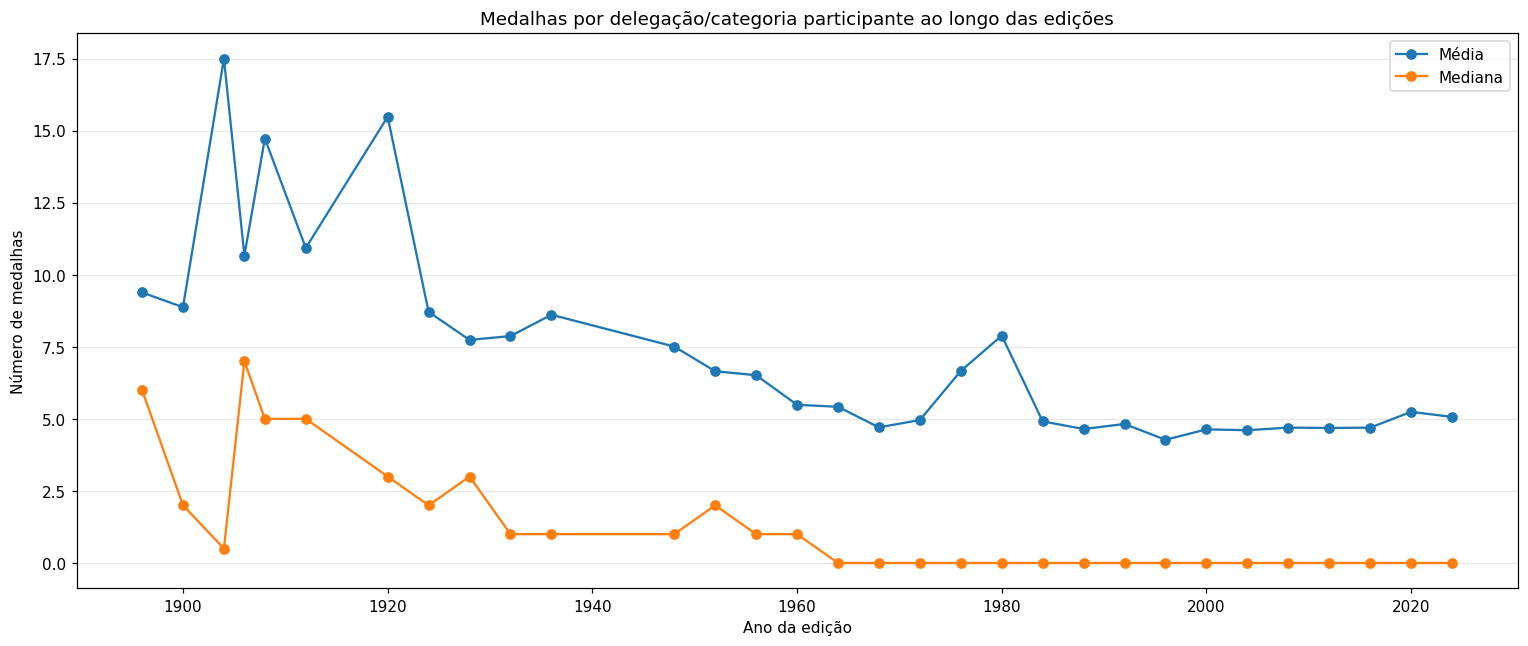

In [5]:
plt.figure(figsize=(14, 6))

plt.plot(
    resumo_edicoes['year'],
    resumo_edicoes['media_medalhas'],
    marker='o',
    label='Média'
)

plt.plot(
    resumo_edicoes['year'],
    resumo_edicoes['mediana_medalhas'],
    marker='o',
    label='Mediana'
)

plt.title('Medalhas por delegação/categoria participante ao longo das edições')
plt.xlabel('Ano da edição')
plt.ylabel('Número de medalhas')
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


**Análise e Resposta**

Os dados mostram que o contexto competitivo dos Jogos Olímpicos mudou substancialmente ao longo do período analisado. Em 1896, a base registra **13 delegações/categorias participantes e 122 medalhas**, enquanto em 2024 aparecem **206 delegações participantes e 1.044 medalhas**. Portanto, tanto a quantidade de delegações quanto a quantidade de medalhas disponíveis aumentaram consideravelmente ao longo da história dos Jogos.

Entretanto, o aumento do número total de medalhas não significou um aumento equivalente no número de medalhas conquistadas pelo país participante típico. Em 1896, a média era de **9,38 medalhas por delegação/categoria** e a mediana era de **6**. Em 2024, apesar de haver muito mais medalhas disponíveis, a média foi de aproximadamente **5,07 medalhas por delegação**, enquanto a mediana foi **zero**.

A mediana igual a zero nas edições mais recentes significa que pelo menos metade dos países participantes terminou essas edições sem conquistar nenhuma medalha. Esse padrão aparece de forma persistente na base a partir de 1964. Ao mesmo tempo, existem países que conquistam dezenas ou até mais de uma centena de medalhas em uma única edição, fazendo com que a média seja consideravelmente superior à mediana.

Também houve crescimento no número absoluto de países medalhistas. Em 1896, **11 dos 13 participantes** conquistaram pelo menos uma medalha. Em 2024, **92 dos 206 participantes** conquistaram medalhas. Assim, embora hoje muito mais países alcancem o pódio em números absolutos, o crescimento do número de participantes foi ainda maior.

Portanto, **o desempenho olímpico dos países varia bastante entre as edições tanto em nível quanto em distribuição**. As primeiras edições possuíam poucos participantes e um número relativamente elevado de medalhas por país. Com a expansão dos Jogos, aumentaram simultaneamente o número de países e o total de medalhas, mas o número de medalhas do país típico diminuiu. Nas edições contemporâneas, muitos países terminam sem medalhas, enquanto alguns apresentam totais muito elevados.

Essa diferença entre média e mediana também indica que a distribuição de medalhas é bastante assimétrica. A questão seguinte permitirá investigar mais diretamente até que ponto essas medalhas se concentram em um grupo reduzido de países.


### 2. Como as medalhas estão distribuídas entre os países participantes? Elas se concentram em um grupo relativamente pequeno de países?

**Transformação dos Dados**

Para analisar a distribuição das medalhas entre os países participantes, foram consideradas todas as edições dos Jogos Olímpicos de Verão disponíveis na base, entre 1896 e 2024.

Como a base abrange mais de um século de Jogos Olímpicos, alguns códigos representam delegações ou entidades históricas, como União Soviética e Alemanha Oriental. Por isso, nesta análise, os países são identificados pelos códigos dos Comitês Olímpicos Nacionais (NOCs) registrados na base.

Primeiramente, foi calculado o total de medalhas conquistado por cada NOC ao longo de todo o período. Em seguida, os NOCs foram ordenados do maior para o menor número de medalhas e foram calculadas suas participações percentual e acumulada no total de medalhas.


In [6]:
# Remove apenas observações sem código NOC identificável
df_q2 = df_olimpico_completo[
    df_olimpico_completo['noc'].notna()
].copy()

# Total de medalhas de cada NOC em todas as edições
medalhas_por_noc = (
    df_q2
    .groupby('noc', as_index=False)
    .agg(total_medalhas=('total', 'sum'))
    .sort_values('total_medalhas', ascending=False)
    .reset_index(drop=True)
)

# Participação de cada NOC no total de medalhas
total_medalhas_historico = medalhas_por_noc['total_medalhas'].sum()

medalhas_por_noc['participacao_pct'] = (
    medalhas_por_noc['total_medalhas']
    / total_medalhas_historico
    * 100
)

medalhas_por_noc['participacao_acumulada_pct'] = (
    medalhas_por_noc['participacao_pct'].cumsum()
)

medalhas_por_noc['posicao'] = (
    medalhas_por_noc.index + 1
)

display(medalhas_por_noc.head(20))

,noc,total_medalhas,participacao_pct,participacao_acumulada_pct,posicao
0,USA,2806,15.419277,15.419277,1
1,GBR,1019,5.599516,21.018793,2
2,URS,1010,5.550060,26.568854,3
3,FRA,877,4.819211,31.388065,4
4,GER,845,4.643367,36.031432,5
5,CHN,727,3.994944,40.026377,6
6,ITA,688,3.780635,43.807012,7
7,AUS,597,3.280580,47.087592,8
8,HUN,544,2.989339,50.076932,9
9,JPN,544,2.989339,53.066271,10


A concentração histórica das medalhas pode ser visualizada pela participação acumulada dos NOCs, ordenados do maior para o menor número de medalhas:


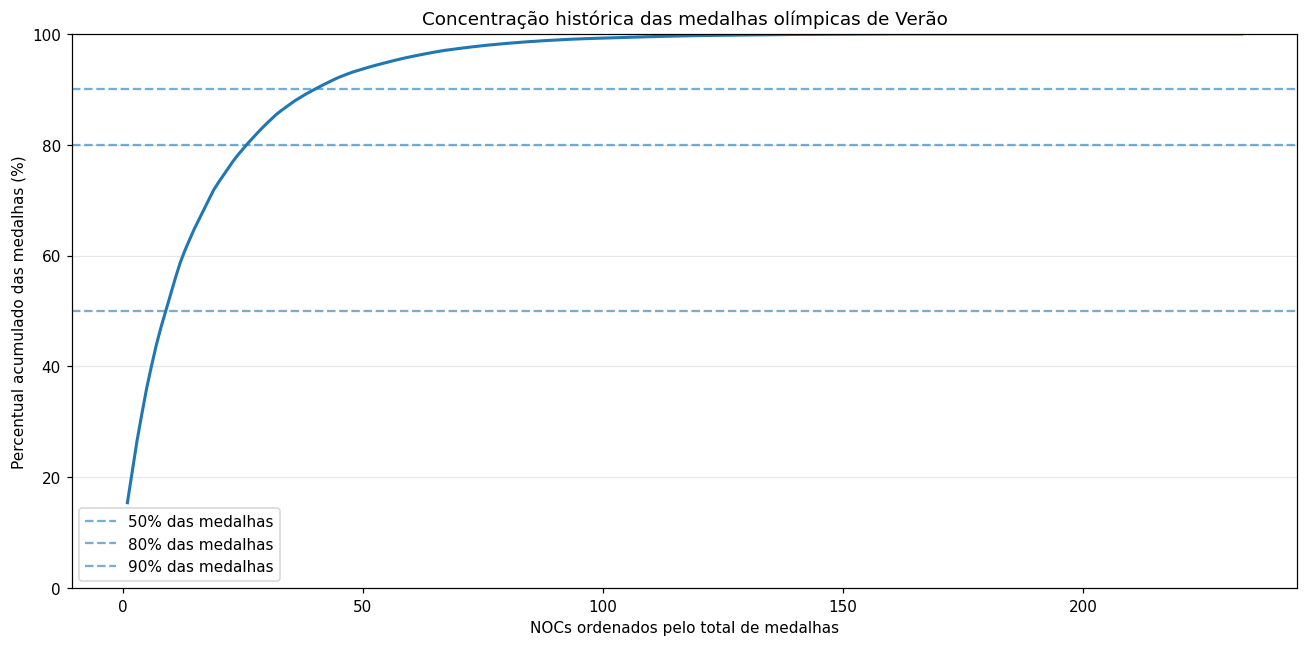

In [7]:

plt.figure(figsize=(12, 6))

plt.plot(
    medalhas_por_noc['posicao'],
    medalhas_por_noc['participacao_acumulada_pct'],
    linewidth=2
)

plt.axhline(50, linestyle='--', alpha=0.6, label='50% das medalhas')
plt.axhline(80, linestyle='--', alpha=0.6, label='80% das medalhas')
plt.axhline(90, linestyle='--', alpha=0.6, label='90% das medalhas')

plt.title('Concentração histórica das medalhas olímpicas de Verão')
plt.xlabel('NOCs ordenados pelo total de medalhas')
plt.ylabel('Percentual acumulado das medalhas (%)')

plt.ylim(0, 100)
plt.grid(axis='y', alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


Como o número de participantes aumentou muito ao longo da história dos Jogos, também é útil verificar se essa concentração ocorre dentro de cada edição. Para isso, foi calculada a parcela das medalhas conquistada pelos dez NOCs com maior número de medalhas em cada edição.


In [8]:
# Ordena os países dentro de cada edição
ranking_edicao = (
    df_q2
    .sort_values(
        ['year', 'total', 'noc'],
        ascending=[True, False, True]
    )
    .copy()
)

# Posição do país dentro da edição
ranking_edicao['posicao_edicao'] = (
    ranking_edicao
    .groupby('year')
    .cumcount() + 1
)

# Total de medalhas distribuídas em cada edição
ranking_edicao['total_edicao'] = (
    ranking_edicao
    .groupby('year')['total']
    .transform('sum')
)

# Participação percentual de cada país
ranking_edicao['participacao_pct'] = (
    ranking_edicao['total']
    / ranking_edicao['total_edicao']
    * 100
)

# Participação conjunta dos 10 primeiros de cada edição
concentracao_top10 = (
    ranking_edicao[
        ranking_edicao['posicao_edicao'] <= 10
    ]
    .groupby('year', as_index=False)
    .agg(
        participacao_top10=('participacao_pct', 'sum')
    )
)

concentracao_top10


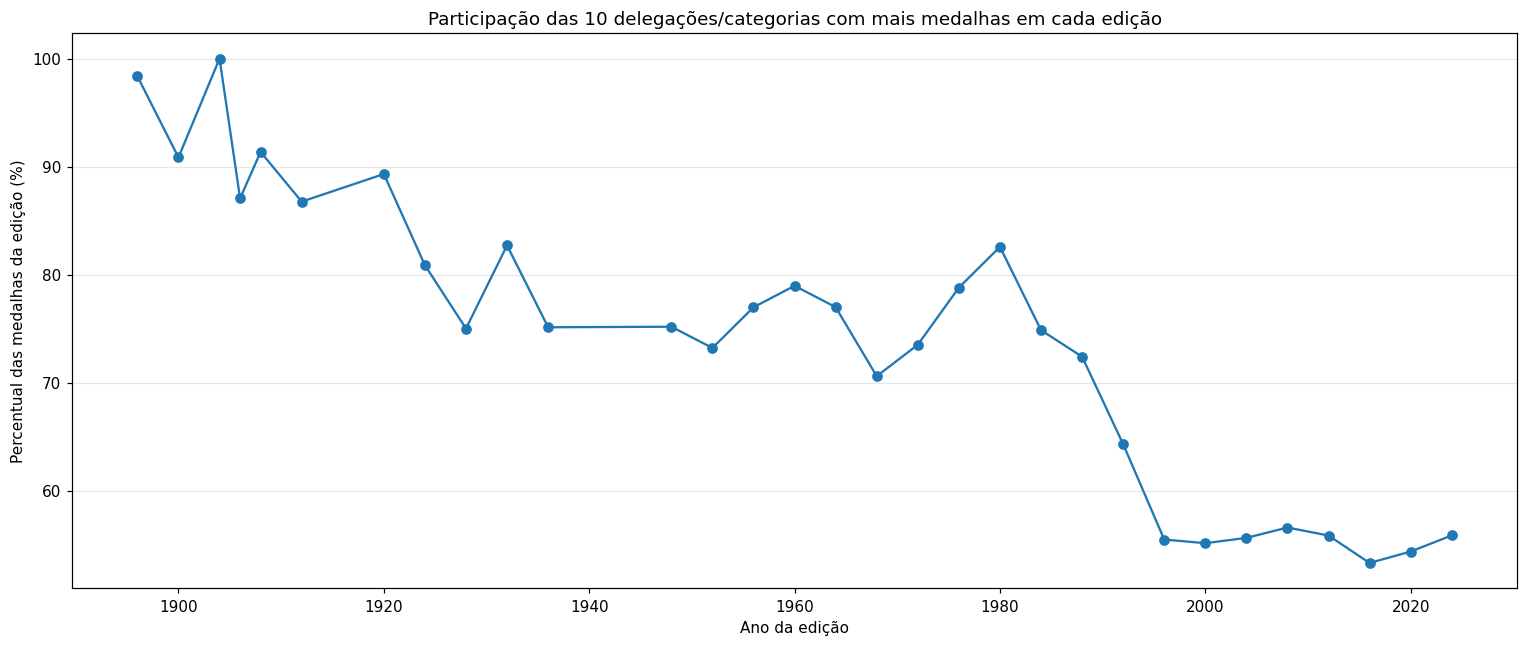

In [9]:
plt.figure(figsize=(14, 6))

plt.plot(
    concentracao_top10['year'],
    concentracao_top10['participacao_top10'],
    marker='o'
)

plt.title('Participação das 10 delegações/categorias com mais medalhas em cada edição')
plt.xlabel('Ano da edição')
plt.ylabel('Percentual das medalhas da edição (%)')

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


**Análise e Resposta**

A distribuição histórica das medalhas apresenta forte concentração. Ao longo das edições de Verão analisadas, aparecem **233 códigos olímpicos diferentes, incluindo a categoria MIX**, dos quais **158 conquistaram pelo menos uma medalha** e **75 nunca conquistaram medalhas** no período registrado na base.

No total, foram contabilizadas **18.198 medalhas**. Entretanto, essas medalhas estão distribuídas de maneira bastante desigual. Apenas os **9 NOCs com mais medalhas acumuladas concentram pouco mais de 50% de todas as medalhas** do período. Considerando os dez primeiros, essa participação chega a aproximadamente **53,1%**.

A concentração continua evidente quando ampliamos o grupo: os **20 NOCs com mais medalhas acumulam aproximadamente 73,2%** de todas as medalhas, enquanto apenas **40 NOCs concentram cerca de 90,0%** do total histórico. Portanto, uma parcela relativamente pequena das delegações é responsável pela maior parte das medalhas distribuídas ao longo dos Jogos.

Esse resultado histórico, entretanto, deve ser interpretado com cuidado. Países que participaram de muitas edições tiveram mais oportunidades de acumular medalhas, e a base contém também delegações históricas que não existem mais na mesma forma, como a União Soviética e a Alemanha Oriental. Por isso, o total acumulado não deve ser interpretado simplesmente como um ranking atual de desempenho.

A análise por edição confirma, porém, que a concentração não é apenas consequência do acúmulo histórico. Nas edições mais recentes, os dez países com maior número de medalhas continuam concentrando mais da metade das medalhas disponíveis. Em 2000, os dez primeiros receberam aproximadamente **55,1%** das medalhas; em 2008, **56,6%**; em 2016, **53,3%**; e em 2024, **55,8%**.

Em 2024, por exemplo, havia **206 NOCs participantes**, mas apenas **92 conquistaram ao menos uma medalha**, enquanto **114 terminaram a edição sem medalhas**. Além disso, os vinte países com maior desempenho concentraram aproximadamente **71,5%** de todas as medalhas daquela edição.

Assim, os dados indicam que **as medalhas olímpicas estão fortemente concentradas em um grupo relativamente pequeno de países**. Essa concentração era ainda mais extrema nas primeiras edições, quando o número de participantes era menor, e diminuiu com a expansão dos Jogos. Mesmo assim, permanece elevada nas edições contemporâneas: mais de metade das medalhas continua sendo conquistada pelos dez países de maior desempenho de cada edição.


### 3. Países com populações maiores tendem a conquistar mais medalhas?

**Transformação dos Dados**

Como esta pergunta envolve um indicador socioeconômico, foram consideradas apenas as edições dos Jogos Olímpicos de Verão entre **1960 e 2024**, período de sobreposição com os dados de população do World Bank.

A unidade de análise continua sendo **país × edição olímpica**. Países que participaram de uma edição e não conquistaram medalhas permanecem na base com `total = 0`. Para esta pergunta, são excluídas apenas as observações que não possuem informação de população.

A população apresenta valores muito diferentes entre os países, variando por várias ordens de grandeza. Por isso, o gráfico de dispersão utiliza escala logarítmica no eixo da população. Além da inspeção visual, é calculada a correlação de Spearman, que mede a associação monotônica entre duas variáveis por meio de suas posições no ranking e é menos sensível que a correlação de Pearson à forte assimetria da população e a valores extremos.

Como a população mundial também cresceu ao longo do período, a análise é complementada agrupando os países em **quartis de população dentro de cada edição**. Dessa forma, a comparação é feita entre países relativamente menores e maiores no contexto de cada Olimpíada, evitando comparar diretamente o tamanho populacional absoluto de 1960 com o de 2024.


In [10]:
# Seleciona apenas observações com população disponível
df_q3 = (
    df_socioeconomico
    .dropna(subset=['population'])
    .query('population > 0')
    .sort_values(['year', 'noc'])
    .copy()
)

observacoes_totais_q3 = len(df_socioeconomico)
observacoes_validas_q3 = len(df_q3)
ausentes_populacao = df_socioeconomico['population'].isna().sum()

print(f'Observações no recorte 1960–2024: {observacoes_totais_q3}')
print(f'Observações com população disponível: {observacoes_validas_q3}')
print(f'Observações sem população: {ausentes_populacao}')

# Correlação de Spearman entre população e total de medalhas
correlacao_spearman_pop = (
    df_q3[['population', 'total']]
    .corr(method='spearman')
    .loc['population', 'total']
)

print(f'Correlação de Spearman: {correlacao_spearman_pop:.3f}')


Observações no recorte 1960–2024: 2676
Observações com população disponível: 2583
Observações sem população: 93
Correlação de Spearman: 0.477


O gráfico de dispersão abaixo mostra a relação entre população e número de medalhas para cada observação país × edição. A escala logarítmica no eixo horizontal é utilizada porque existem diferenças de várias ordens de grandeza entre as populações dos países.


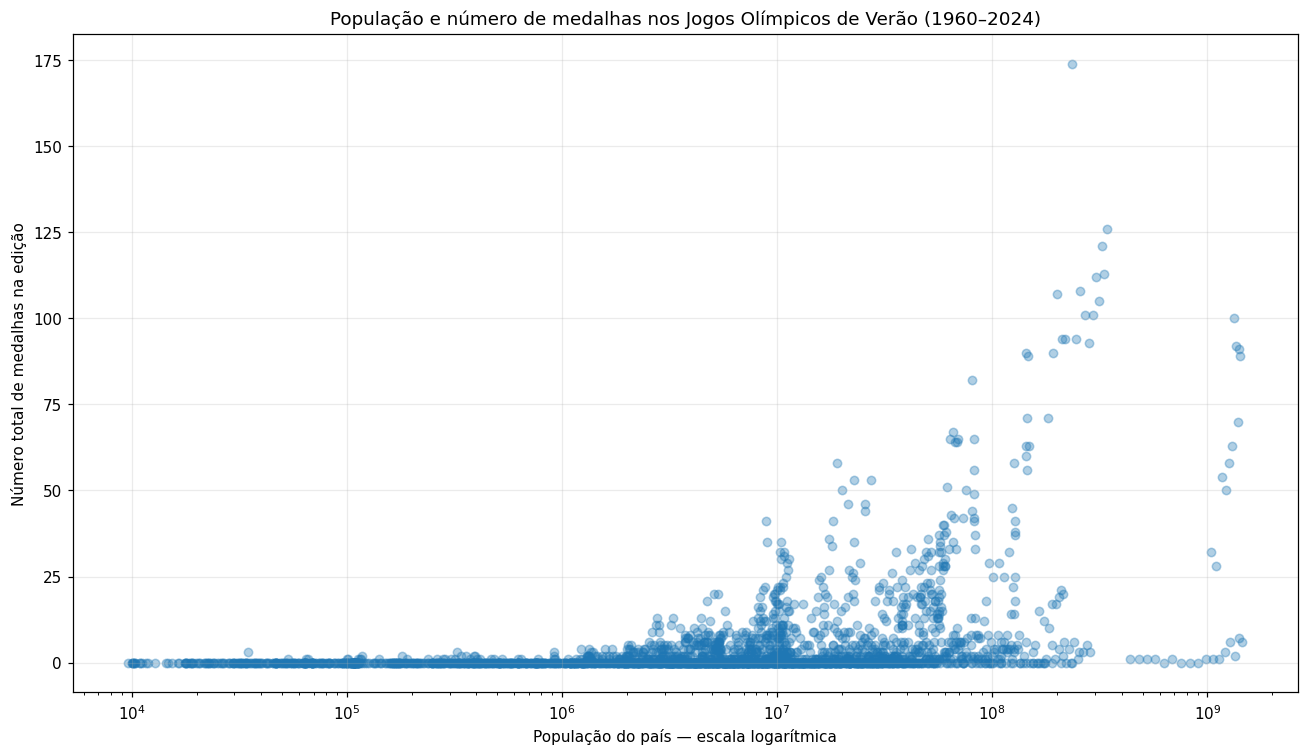

In [11]:

plt.figure(figsize=(12, 7))

plt.scatter(
    df_q3['population'],
    df_q3['total'],
    alpha=0.35,
    s=30
)

plt.xscale('log')

plt.title('População e número de medalhas nos Jogos Olímpicos de Verão (1960–2024)')
plt.xlabel('População do país — escala logarítmica')
plt.ylabel('Número total de medalhas na edição')

plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


Para complementar o gráfico de dispersão, os países foram divididos em quatro grupos de tamanho populacional **dentro de cada edição**. O primeiro quartil reúne os países relativamente menos populosos daquela edição, enquanto o quarto quartil reúne os relativamente mais populosos.


In [12]:
# Cria quartis de população separadamente em cada edição
# O rank(method='first') evita problemas de corte quando existem valores empatados.
rotulos_quartis = [
    'Q1 - menor população',
    'Q2',
    'Q3',
    'Q4 - maior população'
]

df_q3['quartil_populacao'] = (
    df_q3
    .groupby('year')['population']
    .transform(
        lambda x: pd.qcut(
            x.rank(method='first'),
            q=4,
            labels=rotulos_quartis
        )
    )
)

# Resume o desempenho em cada quartil
resumo_quartis_pop = (
    df_q3
    .groupby('quartil_populacao', observed=False)
    .agg(
        observacoes=('total', 'size'),
        media_medalhas=('total', 'mean'),
        mediana_medalhas=('total', 'median'),
        proporcao_medalhistas=(
            'total',
            lambda x: (x > 0).mean() * 100
        )
    )
    .reset_index()
)

resumo_quartis_pop


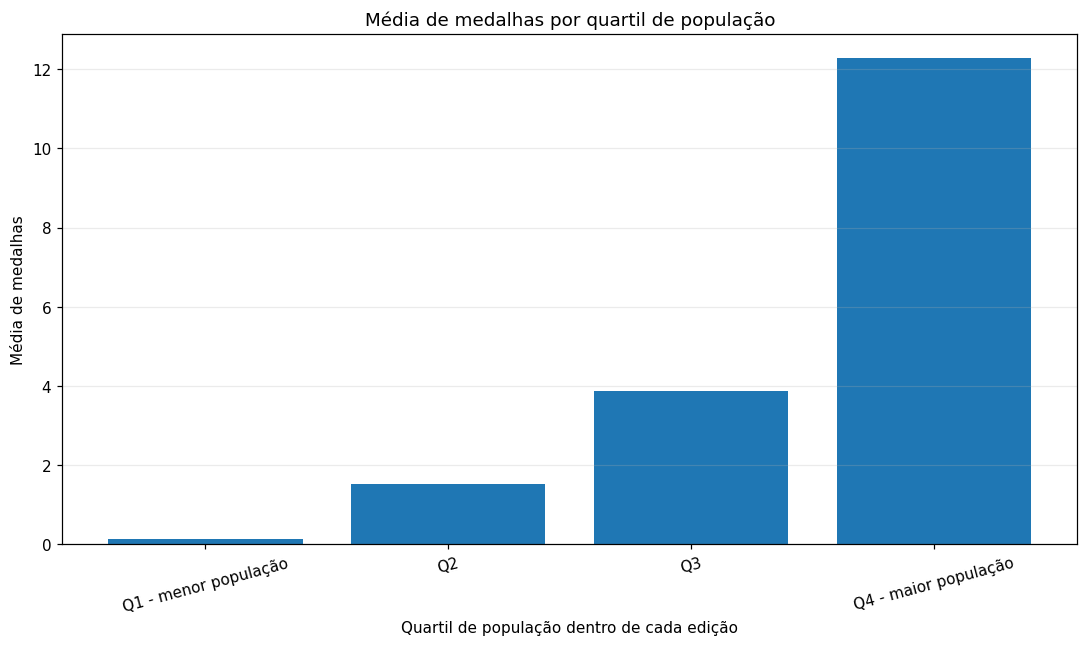

In [13]:
plt.figure(figsize=(10, 6))

plt.bar(
    resumo_quartis_pop['quartil_populacao'].astype(str),
    resumo_quartis_pop['media_medalhas']
)

plt.title('Média de medalhas por quartil de população')
plt.xlabel('Quartil de população dentro de cada edição')
plt.ylabel('Média de medalhas')

plt.xticks(rotation=15)
plt.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()


**Análise e Resposta**

No recorte de 1960 a 2024, a base contém **2.676 observações país × edição**, das quais **2.583 possuem informação de população** e podem ser utilizadas nesta análise. As 93 observações restantes foram mantidas como ausentes na base geral e são excluídas apenas desta pergunta. Entre elas estão algumas delegações históricas, como União Soviética e Alemanha Oriental, para as quais não existe uma correspondência direta e defensável com os países atuais do World Bank. Essa ausência deve ser considerada uma limitação da análise.

O gráfico de dispersão sugere uma **associação positiva entre população e número de medalhas**: observações correspondentes a países mais populosos aparecem com maior frequência entre os maiores totais de medalhas. Entretanto, existe grande dispersão. Há países muito populosos que conquistam poucas ou nenhuma medalha e, ao mesmo tempo, países de população bem menor que apresentam resultados relativamente elevados.

A correlação de Spearman entre população e total de medalhas é de aproximadamente **0,48**. O valor positivo confirma a tendência observada no gráfico: à medida que a população aumenta, o número de medalhas tende também a ocupar posições mais altas. No entanto, a relação está longe de ser perfeita, mostrando que o tamanho da população, isoladamente, não determina o desempenho olímpico.

A comparação por quartis reforça esse padrão. Dentro de cada edição, os países pertencentes ao **quartil de menor população (Q1)** conquistaram, em média, aproximadamente **0,14 medalha por participação**, e apenas cerca de **9,5%** dessas observações correspondem a países que conquistaram pelo menos uma medalha. No segundo quartil, a média sobe para aproximadamente **1,54 medalha**, e no terceiro, para **3,87 medalhas**.

No **quartil de maior população (Q4)**, a média alcança aproximadamente **12,28 medalhas por participação**, e cerca de **69,3%** das observações correspondem a países medalhistas. A mediana desse grupo é de **3 medalhas**, enquanto a mediana dos três primeiros quartis é zero.

Portanto, **os dados indicam que países com populações maiores tendem a conquistar mais medalhas olímpicas**. A associação aparece tanto no gráfico de dispersão quanto na comparação entre grupos de população. Contudo, a ampla variabilidade dentro de cada faixa populacional mostra que população não é suficiente para explicar o desempenho: países de tamanhos semelhantes podem apresentar resultados olímpicos muito diferentes.

Além disso, essa análise identifica apenas uma associação. Não é possível concluir que uma população maior cause diretamente um melhor desempenho olímpico. Outros fatores, inclusive econômicos, podem estar relacionados ao resultado, o que será explorado nas perguntas seguintes.


### 4. Existe associação entre o PIB de um país e seu número de medalhas conquistadas?

**Transformação dos Dados**

Como esta pergunta utiliza o PIB, foram consideradas apenas as edições dos Jogos Olímpicos de Verão entre **1960 e 2024**, período de sobreposição com os dados do World Bank.

A unidade de análise permanece sendo **país × edição olímpica**, e países participantes que não conquistaram medalhas continuam representados com `total = 0`. Para esta pergunta, são excluídas somente as observações sem informação de PIB.

O indicador utilizado é o PIB em **dólares correntes** (`NY.GDP.MKTP.CD`). Como valores monetários correntes de anos muito distantes não são diretamente comparáveis devido, entre outros fatores, à inflação e a variações cambiais, a análise não se baseará apenas nos valores absolutos combinados ao longo de todo o período.

O gráfico de dispersão utiliza escala logarítmica no eixo do PIB para representar adequadamente países cujas economias diferem por várias ordens de grandeza. Para a medida de associação principal, cada país recebe também sua **posição percentual de PIB dentro da própria edição olímpica**. Assim, comparamos se países relativamente maiores economicamente em cada edição tendem a conquistar mais medalhas, sem depender da comparação direta entre dólares de 1960 e dólares de 2024.


In [14]:
# Seleciona somente observações com PIB disponível
df_q4 = (
    df_socioeconomico
    .dropna(subset=['gdp'])
    .query('gdp > 0')
    .sort_values(['year', 'noc'])
    .copy()
)

observacoes_totais_q4 = len(df_socioeconomico)
observacoes_validas_q4 = len(df_q4)
ausentes_gdp = df_socioeconomico['gdp'].isna().sum()

print(f'Observações no recorte 1960–2024: {observacoes_totais_q4}')
print(f'Observações com PIB disponível: {observacoes_validas_q4}')
print(f'Observações sem PIB: {ausentes_gdp}')

# Posição percentual do PIB dentro de cada edição.
# Valores próximos de 1 representam os maiores PIBs daquela edição.
df_q4['percentil_gdp_edicao'] = (
    df_q4
    .groupby('year')['gdp']
    .rank(method='average', pct=True)
)

# Correlação de Spearman entre posição relativa do PIB e medalhas
correlacao_spearman_gdp = (
    df_q4[['percentil_gdp_edicao', 'total']]
    .corr(method='spearman')
    .loc['percentil_gdp_edicao', 'total']
)

print(
    'Correlação de Spearman entre posição relativa do PIB '
    f'e medalhas: {correlacao_spearman_gdp:.3f}'
)


Observações no recorte 1960–2024: 2676
Observações com PIB disponível: 2446
Observações sem PIB: 230
Correlação de Spearman entre posição relativa do PIB e medalhas: 0.668


O gráfico abaixo mostra a relação entre o PIB e o número de medalhas nas observações país × edição. A escala logarítmica no eixo horizontal é necessária porque os PIBs apresentam diferenças de várias ordens de grandeza. Como o PIB está expresso em dólares correntes, o gráfico deve ser interpretado principalmente como uma visualização exploratória da associação, e não como uma comparação direta de níveis monetários entre décadas.


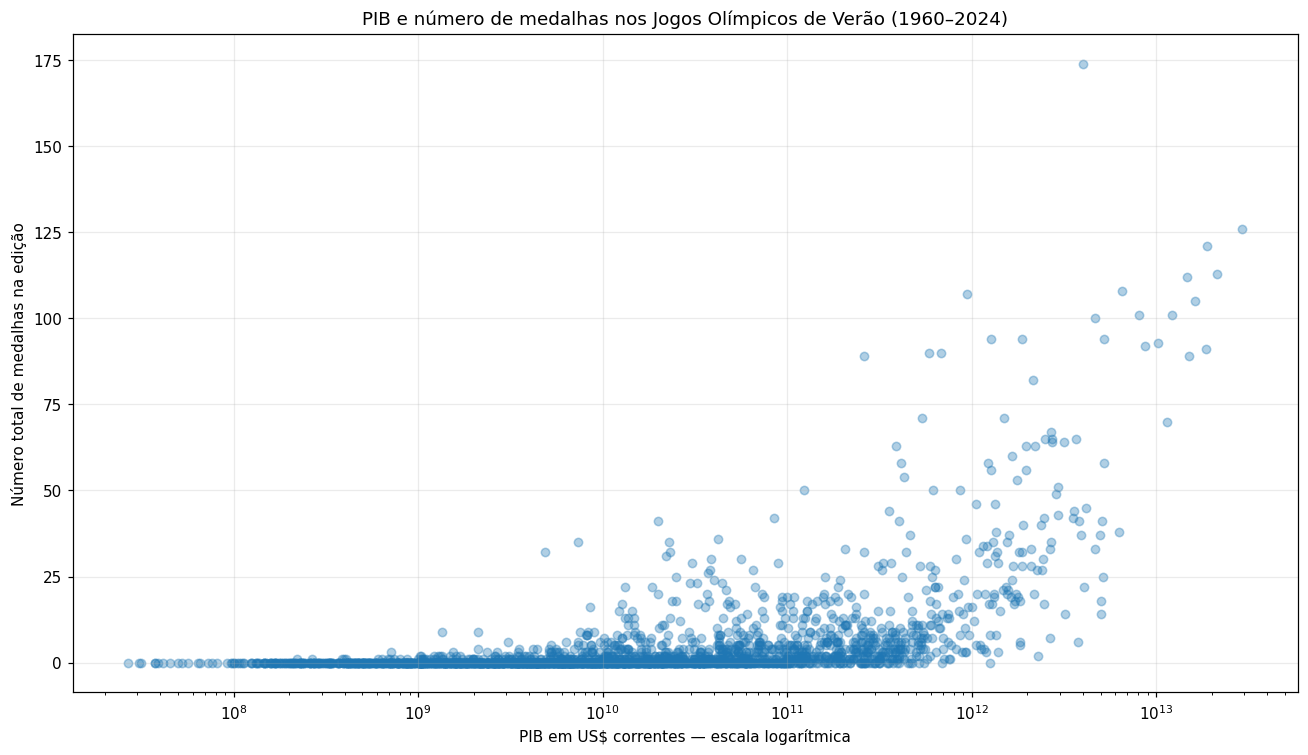

In [15]:

plt.figure(figsize=(12, 7))

plt.scatter(
    df_q4['gdp'],
    df_q4['total'],
    alpha=0.35,
    s=30
)

plt.xscale('log')

plt.title('PIB e número de medalhas nos Jogos Olímpicos de Verão (1960–2024)')
plt.xlabel('PIB em US$ correntes — escala logarítmica')
plt.ylabel('Número total de medalhas na edição')

plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


Para tornar a comparação entre diferentes edições mais adequada, os países foram divididos em **quartis de PIB dentro de cada edição**. O primeiro quartil reúne os países com os menores PIBs relativos daquela edição e o quarto quartil reúne os maiores. Em seguida, são comparados o número médio e mediano de medalhas e a proporção de países que conquistaram pelo menos uma medalha.


In [16]:
# Quartis de PIB calculados separadamente em cada edição
rotulos_quartis_gdp = [
    'Q1 - menor PIB',
    'Q2',
    'Q3',
    'Q4 - maior PIB'
]

df_q4['quartil_gdp'] = (
    df_q4
    .groupby('year')['gdp']
    .transform(
        lambda x: pd.qcut(
            x.rank(method='first'),
            q=4,
            labels=rotulos_quartis_gdp
        )
    )
)

resumo_quartis_gdp = (
    df_q4
    .groupby('quartil_gdp', observed=False)
    .agg(
        observacoes=('total', 'size'),
        media_medalhas=('total', 'mean'),
        mediana_medalhas=('total', 'median'),
        proporcao_medalhistas=(
            'total',
            lambda x: (x > 0).mean() * 100
        )
    )
    .reset_index()
)

resumo_quartis_gdp


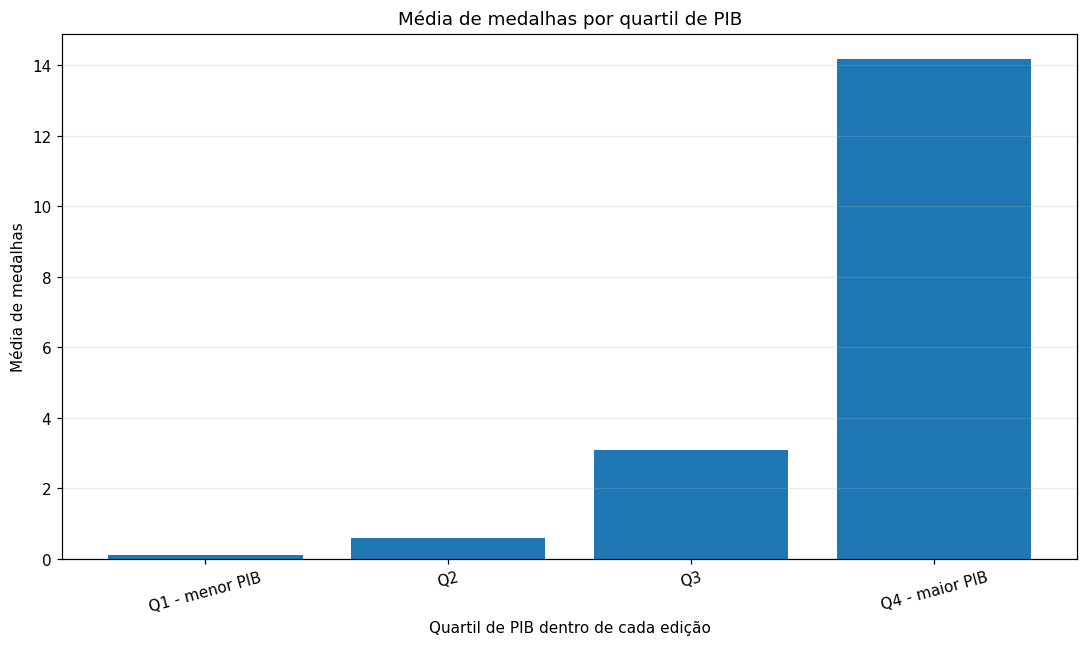

In [17]:
plt.figure(figsize=(10, 6))

plt.bar(
    resumo_quartis_gdp['quartil_gdp'].astype(str),
    resumo_quartis_gdp['media_medalhas']
)

plt.title('Média de medalhas por quartil de PIB')
plt.xlabel('Quartil de PIB dentro de cada edição')
plt.ylabel('Média de medalhas')

plt.xticks(rotation=15)
plt.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()


**Análise e Resposta**

No período de 1960 a 2024, a base possui **2.676 observações país × edição**. Destas, **2.446 possuem informação de PIB** e são utilizadas nesta pergunta; **230 observações não possuem o indicador** e são excluídas apenas desta análise.

O gráfico de dispersão apresenta um padrão de associação positiva: os maiores totais de medalhas aparecem com maior frequência entre países de PIB elevado. Ao mesmo tempo, a dispersão é considerável, pois países com níveis econômicos semelhantes podem apresentar números de medalhas bastante diferentes.

Para evitar que a comparação entre valores de PIB em dólares correntes de décadas diferentes distorça a interpretação, foi calculada a posição relativa do PIB de cada país dentro de sua própria edição olímpica. A correlação de Spearman entre essa posição relativa e o total de medalhas é de aproximadamente **0,67**, indicando uma associação positiva relativamente clara: países que ocupam posições mais altas na distribuição de PIB de uma edição tendem também a ocupar posições mais altas em número de medalhas.

A comparação por quartis reforça esse resultado. Entre os países do **quartil de menor PIB (Q1)**, a média é de aproximadamente **0,11 medalha por participação**, e apenas cerca de **7,3%** das observações correspondem a países que conquistaram pelo menos uma medalha. No segundo quartil, a média sobe para cerca de **0,58 medalha**, e no terceiro quartil chega a aproximadamente **3,09 medalhas**.

No **quartil de maior PIB (Q4)**, a média alcança aproximadamente **14,19 medalhas por participação**. Além disso, cerca de **87,1%** das observações desse grupo correspondem a países medalhistas, e a mediana é de **5 medalhas**. Nos três primeiros quartis, a mediana é zero.

Portanto, **os dados mostram uma associação positiva entre PIB total e desempenho olímpico medido pelo número de medalhas**. Países com economias relativamente maiores dentro de cada edição tendem a conquistar mais medalhas e apresentam uma proporção observada muito maior de participantes com ao menos uma medalha.

Essa associação, entretanto, não implica causalidade. O PIB total também está relacionado ao tamanho da população e não informa como a riqueza está distribuída entre os habitantes nem quanto um país efetivamente investe em esporte. Assim, não é possível concluir que um PIB maior, por si só, cause um melhor desempenho olímpico. A próxima pergunta, ao utilizar o PIB per capita, permite investigar se a relação se mantém quando o tamanho da economia é considerado de uma forma diferente.


### 5. A relação observada muda quando utilizamos PIB per capita em vez de PIB total?

**Transformação dos Dados**

Foram consideradas as edições dos Jogos Olímpicos de Verão entre **1960 e 2024**. Para comparar os indicadores em condições equivalentes, esta pergunta utiliza somente observações país × edição com **PIB total e PIB per capita disponíveis e positivos**. Os países participantes sem medalhas permanecem com `total = 0`.

O PIB total representa o tamanho da economia, enquanto o PIB per capita representa o valor da produção por habitante; este último não mede diretamente distribuição de renda ou investimento esportivo. Como ambos estão em dólares correntes, calculamos a **posição percentual de cada indicador dentro da própria edição**, seguindo o procedimento da pergunta 4. As correlações de Spearman são calculadas na mesma amostra, entre cada posição relativa e o total de medalhas.

Também dividimos os países em quartis de cada indicador dentro de cada edição e calculamos média, mediana e percentual de observações com ao menos uma medalha. Os grupos têm tamanhos semelhantes, mas seus integrantes podem mudar conforme o indicador. Em eventuais empates, o código NOC define uma ordem reproduzível para formar os quartis. As medidas combinadas resumem associações descritivas; não isolam o efeito da edição ou a repetição dos países ao longo do tempo.

In [18]:
# Amostra comum aos dois indicadores, preservando países sem medalhas
indicadores_q5 = {'gdp': 'PIB total', 'gdp_per_capita': 'PIB per capita'}
df_q5 = (df_socioeconomico.dropna(subset=list(indicadores_q5))
         .query('gdp > 0 and gdp_per_capita > 0')
         .sort_values(['year', 'noc']).copy())

correlacoes_q5 = {}
resumos_q5 = []
for coluna, nome in indicadores_q5.items():
    percentil = f'percentil_{coluna}_q5'
    quartil = f'quartil_{coluna}_q5'
    df_q5[percentil] = df_q5.groupby('year')[coluna].rank(method='average', pct=True)
    correlacoes_q5[nome] = df_q5[[percentil, 'total']].corr(method='spearman').iloc[0, 1]
    df_q5[quartil] = df_q5.groupby('year')[coluna].transform(
        lambda x: pd.qcut(x.rank(method='first'), 4, labels=['Q1', 'Q2', 'Q3', 'Q4']))
    resumo = (df_q5.groupby(quartil, observed=False)
              .agg(observacoes=('total', 'size'), media_medalhas=('total', 'mean'),
                   mediana_medalhas=('total', 'median'),
                   proporcao_medalhistas=('total', lambda x: (x > 0).mean() * 100))
              .rename_axis('quartil').reset_index())
    resumo['indicador'] = nome
    resumos_q5.append(resumo)
resumo_quartis_q5 = pd.concat(resumos_q5, ignore_index=True)
display(pd.Series(correlacoes_q5, name='Spearman').round(3).to_frame())
display(resumo_quartis_q5.round(2))

,Spearman
PIB total,0.668
PIB per capita,0.372


,quartil,observacoes,media_medalhas,mediana_medalhas,proporcao_medalhistas,indicador
0,Q1,618,0.11,0.0,7.28,PIB total
1,Q2,612,0.58,0.0,21.24,PIB total
2,Q3,603,3.09,0.0,47.26,PIB total
3,Q4,613,14.19,5.0,87.11,PIB total
4,Q1,618,0.76,0.0,19.58,PIB per capita
5,Q2,612,2.36,0.0,33.50,PIB per capita
6,Q3,603,4.30,0.0,47.93,PIB per capita
7,Q4,613,10.58,2.0,61.83,PIB per capita


Os gráficos abaixo comparam o total de medalhas com a posição relativa de cada indicador na edição. Os mesmos limites e a mesma amostra tornam os painéis comparáveis. Cada ponto representa um país em uma edição; a transparência reduz, mas não elimina, a sobreposição de pontos.

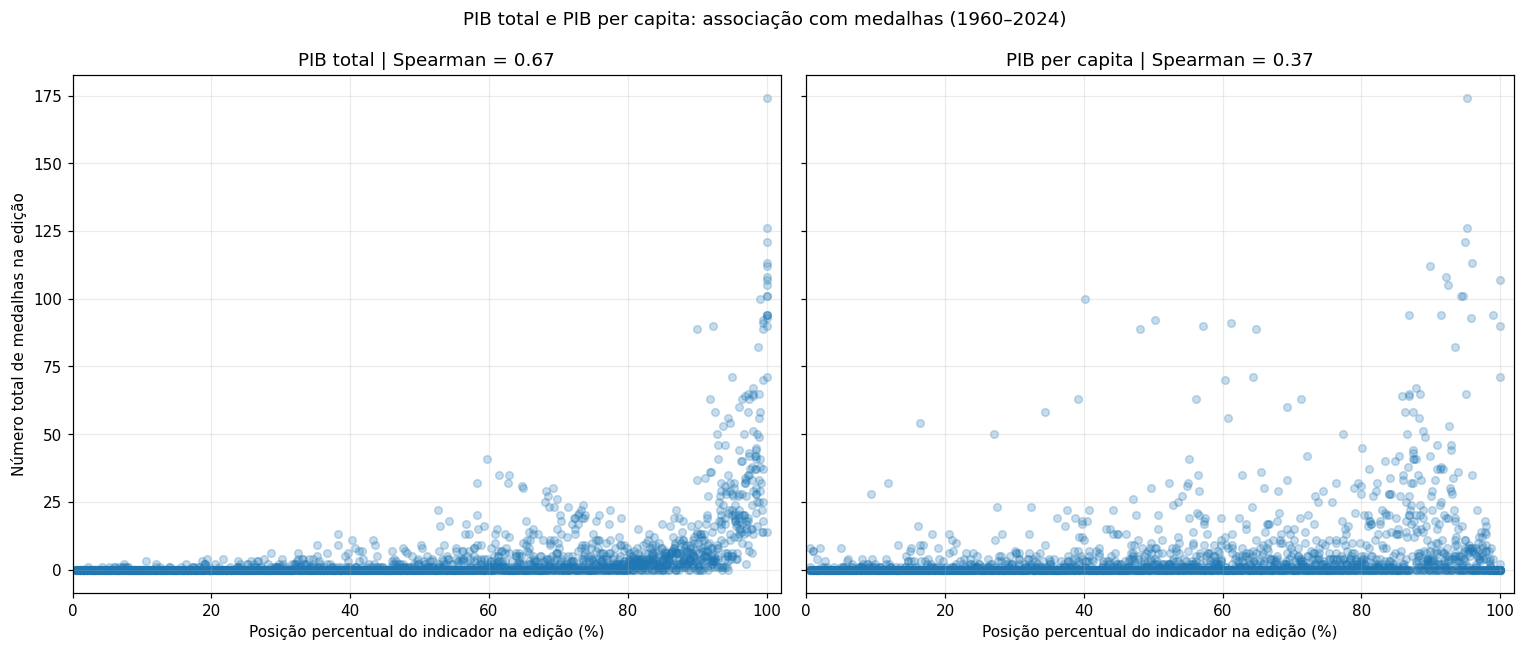

In [19]:

fig, eixos = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)
for eixo, (coluna, nome) in zip(eixos, indicadores_q5.items()):
    eixo.scatter(df_q5[f'percentil_{coluna}_q5'] * 100, df_q5['total'],
                 alpha=0.25, s=25)
    eixo.set_title(f'{nome} | Spearman = {correlacoes_q5[nome]:.2f}')
    eixo.set_xlabel('Posição percentual do indicador na edição (%)')
    eixo.set_xlim(0, 102)
    eixo.grid(alpha=0.25)
eixos[0].set_ylabel('Número total de medalhas na edição')
fig.suptitle('PIB total e PIB per capita: associação com medalhas (1960–2024)')
plt.tight_layout()
plt.show()


A comparação das médias por quartil permite observar se o desempenho se concentra nos países de maior economia e nos países de maior PIB per capita. Q1 reúne os menores valores do indicador na edição; Q4, os maiores. As medianas e proporções de medalhistas estão na tabela anterior para complementar a média, sensível aos maiores totais.

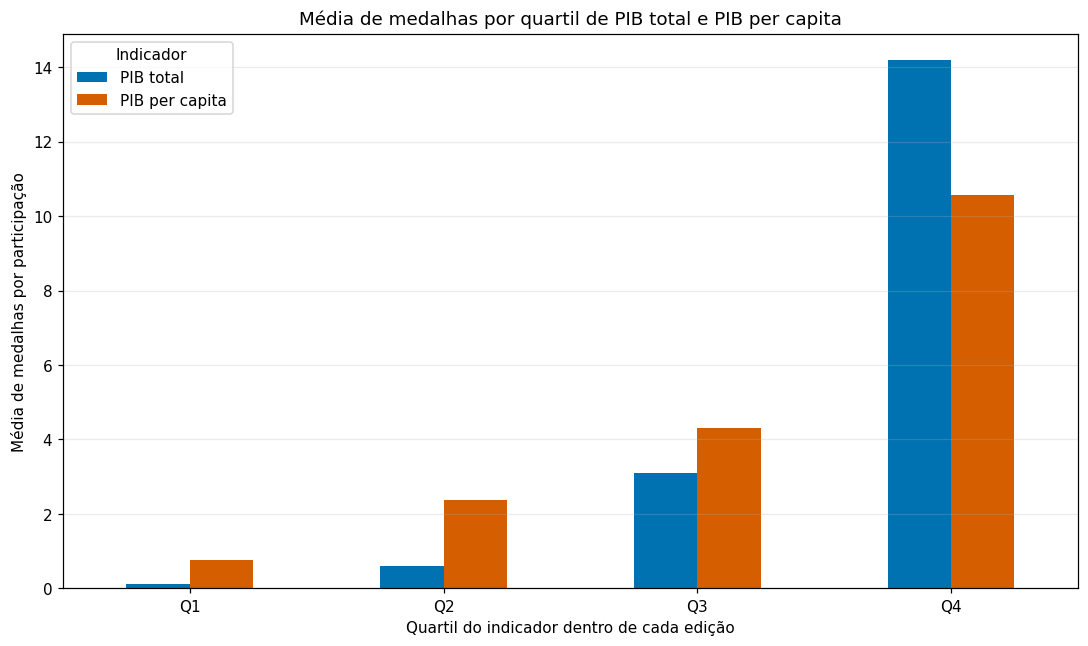

In [20]:
tabela_medias_q5 = resumo_quartis_q5.pivot(index='quartil', columns='indicador', values='media_medalhas')
eixo = tabela_medias_q5[['PIB total', 'PIB per capita']].plot.bar(
    figsize=(10, 6), color=['#0072B2', '#D55E00'], rot=0)
eixo.set_title('Média de medalhas por quartil de PIB total e PIB per capita')
eixo.set_xlabel('Quartil do indicador dentro de cada edição')
eixo.set_ylabel('Média de medalhas por participação')
eixo.legend(title='Indicador')
eixo.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

**Análise e Resposta**

A amostra comum contém **2.446 observações país × edição**, das 2.676 existentes no recorte de 1960 a 2024. As 230 observações restantes não atendem aos critérios de disponibilidade e positividade dos dois indicadores e são excluídas apenas desta pergunta.

A associação com o número de medalhas permanece positiva nos dois casos, mas é **mais forte para o PIB total**. A correlação de Spearman entre a posição relativa do PIB total na edição e o total de medalhas é de aproximadamente **0,67**, enquanto a correlação correspondente ao PIB per capita é de **0,37**. Como o cálculo utiliza as mesmas observações e o mesmo procedimento, essa diferença não decorre de comparar amostras distintas. Ela descreve a associação nessa base, sem constituir um teste de diferença entre correlações.

A comparação por quartis reforça esse resultado. Para o **PIB total**, as médias de medalhas de Q1 a Q4 são aproximadamente **0,11; 0,58; 3,09; e 14,19**. Para o **PIB per capita**, as médias também crescem, mas seguem a sequência **0,76; 2,36; 4,30; e 10,58**. Assim, a distância entre os extremos é maior quando os países são classificados pelo tamanho total da economia.

No quartil superior de PIB total, cerca de **87,1%** das observações correspondem a participantes medalhistas, e a mediana é de **5 medalhas**. No quartil superior de PIB per capita, esses valores são **61,8%** e **2 medalhas**, respectivamente. Nos três primeiros quartis de ambos os indicadores, a mediana é zero, evidenciando que as médias ainda são influenciadas por uma parcela de participantes com resultados mais altos.

Portanto, **a relação muda quando utilizamos PIB per capita: continua positiva, mas se torna menos intensa do que a observada com PIB total**. Uma posição elevada em produção por habitante não se traduz necessariamente em um grande número absoluto de medalhas. O resultado é compatível com a relevância do tamanho da economia e da população para esse tipo de medida de desempenho, mas não demonstra qual desses fatores produz o resultado esportivo.

Essa comparação não controla simultaneamente população, contexto histórico ou características esportivas. Além disso, reúne várias edições e observações repetidas dos mesmos países; o PIB per capita não mede diretamente renda disponível, desigualdade ou recursos destinados ao esporte. Por isso, não podemos concluir que aumentar qualquer um desses indicadores causaria mais medalhas. A próxima pergunta examina diferenças de desempenho entre países com população e PIB per capita relativamente próximos.

### 6. Quais países apresentam desempenho olímpico muito acima ou abaixo do padrão observado para países com características socioeconômicas semelhantes?

**Transformação dos Dados**

Esta pergunta utiliza **a edição de 2024**, a mais recente do recorte de Verão, para comparar países no mesmo contexto competitivo. São mantidos os participantes com população e PIB per capita disponíveis e positivos, inclusive aqueles que não conquistaram medalhas. A análise é um retrato dessa edição, e não uma classificação permanente dos países. A base de atletas contém um registro isolado de ROC em 2024, sem quadro de medalhas correspondente. Esse registro inconsistente é excluído na preparação geral para não tratá-lo como uma delegação russa com zero medalhas. Registros sem NOC ou sem indicadores válidos também não entram na comparação. A contagem de NOCs e a contagem de linhas utilizam apenas códigos identificáveis.

Definimos países semelhantes a partir de **população e PIB per capita**. O PIB total não entra simultaneamente, pois combina o tamanho populacional e a produção por habitante e seria parcialmente redundante. Aplicamos logaritmo natural aos dois indicadores para reduzir suas assimetrias e padronizamos os valores pela média e pelo desvio-padrão da amostra, dando o mesmo peso às duas dimensões.

Para cada país, selecionamos os **dez outros países mais próximos** pela distância euclidiana nesses dois indicadores padronizados. O próprio país é excluído. O padrão de comparação é a **mediana do total de medalhas desses vizinhos**, menos sensível a um único grande medalhista que a média. Calculamos então:

**Diferença de desempenho = medalhas do país − mediana das medalhas dos dez países mais próximos.**

Valores positivos indicam desempenho acima da referência; negativos, abaixo. Apresentamos os cinco maiores desvios de cada sinal, sem definir um limiar de significância estatística. Como dez vizinhos é uma escolha metodológica, também verificamos os resultados com cinco e quinze. Mesmo os vizinhos mais próximos podem ser bastante diferentes em casos extremos; por isso, exibimos seus códigos e as distâncias para permitir a inspeção das comparações.

In [21]:

ANO_Q6 = 2024
NUM_VIZINHOS_Q6 = 10

df_q6_edicao = df_socioeconomico[df_socioeconomico['year'] == ANO_Q6].copy()
df_q6 = (df_q6_edicao.dropna(subset=['population', 'gdp_per_capita'])
         .query('population > 0 and gdp_per_capita > 0')
         .sort_values('noc').reset_index(drop=True))

# Distâncias socioeconômicas: mesma importância para população e PIB per capita
indicadores_log_q6 = np.log(df_q6[['population', 'gdp_per_capita']])
indicadores_padronizados_q6 = (
    (indicadores_log_q6 - indicadores_log_q6.mean()) / indicadores_log_q6.std(ddof=0)
).to_numpy()
distancias_q6 = np.sqrt(((indicadores_padronizados_q6[:, None, :] -
                         indicadores_padronizados_q6[None, :, :]) ** 2).sum(axis=2))
np.fill_diagonal(distancias_q6, np.inf)  # Exclui o próprio país
ordem_vizinhos_q6 = np.argsort(distancias_q6, axis=1, kind='stable')
assert len(df_q6) > 15, 'A comparação precisa de pelo menos 16 países.'

for k in [5, 10, 15]:
    vizinhos = ordem_vizinhos_q6[:, :k]
    df_q6[f'referencia_{k}'] = np.median(df_q6['total'].to_numpy()[vizinhos], axis=1)
    df_q6[f'diferenca_{k}'] = df_q6['total'] - df_q6[f'referencia_{k}']

vizinhos_q6 = ordem_vizinhos_q6[:, :NUM_VIZINHOS_Q6]
df_q6['vizinhos'] = [', '.join(df_q6.iloc[indices]['noc']) for indices in vizinhos_q6]
df_q6['distancia_media'] = np.take_along_axis(distancias_q6, vizinhos_q6, axis=1).mean(axis=1)
df_q6['distancia_maxima'] = np.take_along_axis(distancias_q6, vizinhos_q6, axis=1).max(axis=1)

# Maiores diferenças positivas e negativas, com desempate determinístico por NOC
acima_q6 = df_q6[df_q6['diferenca_10'] > 0].sort_values(
    ['diferenca_10', 'noc'], ascending=[False, True]).head(5)
abaixo_q6 = df_q6[df_q6['diferenca_10'] < 0].sort_values(
    ['diferenca_10', 'noc'], ascending=[True, True]).head(5)
destaques_q6 = pd.concat([acima_q6, abaixo_q6])
display(destaques_q6[['noc', 'country', 'total', 'referencia_10', 'diferenca_10',
                     'vizinhos', 'distancia_media', 'distancia_maxima']].round(2))

,noc,country,total,referencia_10,diferenca_10,vizinhos,distancia_media,distancia_maxima
183,USA,United States,126,36.5,89.5,"GER, GBR, JPN, FRA, ITA, CAN, KOR, ESP, AUS, KSA",0.93,1.17
36,CHN,People's Republic of China,91,6.0,85.0,"BRA, INA, MEX, IND, TUR, JPN, VIE, IRI, THA, PHI",1.19,1.37
9,AUS,Australia,53,19.0,34.0,"NED, CAN, BEL, KSA, SWE, GBR, UAE, ISR, ITA, FRA",0.39,0.47
63,GBR,Great Britain,65,32.5,32.5,"GER, FRA, ITA, CAN, KOR, ESP, JPN, KSA, AUS, POL",0.31,0.59
59,FRA,France,64,32.5,31.5,"GBR, ITA, GER, KOR, ESP, CAN, JPN, KSA, AUS, POL",0.27,0.50
95,KSA,Saudi Arabia,0,32.5,-32.5,"ESP, KOR, POL, ITA, CAN, FRA, GBR, AUS, ROU, GER",0.32,0.49
54,ESP,Spain,18,36.5,-18.5,"KOR, ITA, KSA, FRA, POL, CAN, GBR, GER, JPN, AUS",0.27,0.49
179,UAE,United Arab Emirates,0,8.0,-8.0,"ISR, BEL, SWE, AUT, HKG, NED, FIN, CZE, NZL, DEN",0.21,0.36
31,CAN,Canada,27,33.5,-6.5,"AUS, GBR, FRA, ITA, KOR, KSA, ESP, GER, NED, POL",0.31,0.54
58,FIN,Finland,0,6.0,-6.0,"NZL, HKG, DEN, AUT, ISR, SWE, UAE, PUR, BEL, KUW",0.24,0.33


O gráfico mostra os maiores desvios em relação à mediana dos dez países mais próximos. A linha vertical em zero indica igualdade com a referência. Os valores são diferenças em número de medalhas, não estimativas de eficiência ou de efeito causal das condições econômicas.

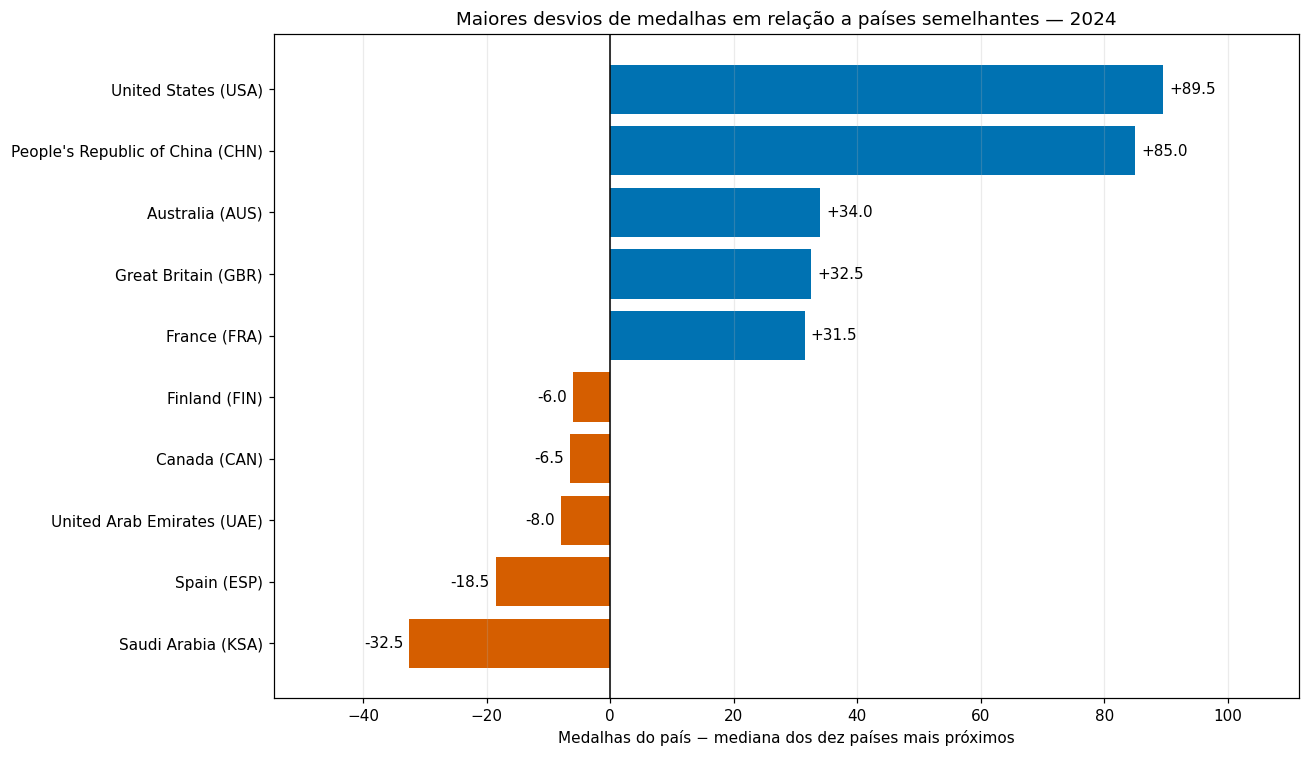

In [22]:
grafico_q6 = destaques_q6.sort_values(['diferenca_10', 'noc'])
fig, eixo = plt.subplots(figsize=(12, 7))
barras = eixo.barh(grafico_q6['country'] + ' (' + grafico_q6['noc'] + ')',
                   grafico_q6['diferenca_10'],
                   color=['#0072B2' if x > 0 else '#D55E00' for x in grafico_q6['diferenca_10']])
eixo.bar_label(barras, fmt='%+.1f', padding=4)
eixo.axvline(0, color='black', linewidth=1)
eixo.margins(x=0.18)
eixo.set_title(f'Maiores desvios de medalhas em relação a países semelhantes — {ANO_Q6}')
eixo.set_xlabel('Medalhas do país − mediana dos dez países mais próximos')
eixo.grid(axis='x', alpha=0.25)
plt.tight_layout()
plt.show()

Para verificar a sensibilidade à escolha dos vizinhos, a tabela seguinte mantém os países destacados pelo critério principal e recalcula suas diferenças com cinco, dez e quinze vizinhos. A manutenção do sinal sugere estabilidade da direção do resultado dentro dessas escolhas, mas não garante a manutenção da posição no ranking.

In [23]:
display(destaques_q6[['noc', 'country', 'diferenca_5', 'diferenca_10', 'diferenca_15']]
        .rename(columns={'diferenca_5': 'Diferença: 5 vizinhos',
                         'diferenca_10': 'Diferença: 10 vizinhos',
                         'diferenca_15': 'Diferença: 15 vizinhos'}).round(1))

,noc,country,Diferença: 5 vizinhos,Diferença: 10 vizinhos,Diferença: 15 vizinhos
183,USA,United States,81.0,89.5,93.0
36,CHN,People's Republic of China,85.0,85.0,85.0
9,AUS,Australia,42.0,34.0,35.0
63,GBR,Great Britain,32.0,32.5,33.0
59,FRA,France,31.0,31.5,37.0
95,KSA,Saudi Arabia,-27.0,-32.5,-32.0
54,ESP,Spain,-14.0,-18.5,-14.0
179,UAE,United Arab Emirates,-7.0,-8.0,-8.0
31,CAN,Canada,-26.0,-6.5,-5.0
58,FIN,Finland,-7.0,-6.0,-5.0


**Análise e Resposta**

Na edição de 2024, a base após a limpeza registra **206 NOCs identificáveis**. Depois da seleção de indicadores válidos, a comparação utiliza **191 países**. Os resultados abaixo são relativos à mediana dos dez países mais próximos em população e PIB per capita, conforme o critério definido nesta seção.

Os maiores desvios positivos aparecem nos **Estados Unidos, China, Austrália, Grã-Bretanha e França**. Os Estados Unidos conquistaram **126 medalhas**, diante de uma referência de **36,5**, uma diferença de **89,5 medalhas**. A China conquistou **91**, com referência de **6**, resultando em uma diferença de **85**. Austrália, Grã-Bretanha e França ficaram, respectivamente, **34; 32,5; e 31,5 medalhas acima** das medianas de seus grupos de comparação.

No sentido oposto, os maiores desvios negativos aparecem na **Arábia Saudita, Espanha, Emirados Árabes Unidos, Canadá e Finlândia**. A Arábia Saudita não conquistou medalhas, enquanto a mediana de seus vizinhos foi de **32,5**. A Espanha conquistou **18 medalhas**, frente à referência de **36,5**, ficando **18,5 abaixo**. Emirados Árabes Unidos, Canadá e Finlândia ficaram, respectivamente, **8; 6,5; e 6 medalhas abaixo** das referências.

A comparação não equivale a classificar esses resultados como bons ou ruins em termos absolutos. O Canadá, por exemplo, conquistou **27 medalhas**, mas sua referência foi de **33,5**, de modo que aparece abaixo do padrão definido. Isso mostra que a pergunta avalia a diferença em relação a um conjunto específico de países, e não simplesmente o total conquistado.

Os dez países destacados **mantêm o sinal de seus desvios** quando a referência passa a utilizar cinco ou quinze vizinhos. A magnitude, entretanto, pode variar bastante: no Canadá, a diferença passa de **−26 medalhas**, com cinco vizinhos, para **−5**, com quinze. Essa sensibilidade impede tratar os valores e as posições como medidas definitivas de desempenho.

Portanto, **países relativamente próximos nas duas características socioeconômicas podem apresentar resultados olímpicos bastante diferentes**. As diferenças observadas mostram os limites de resumir o desempenho apenas por população e PIB per capita. Entretanto, esta análise não mede investimento esportivo, tradição em modalidades, composição das delegações ou outros fatores que poderiam contribuir para essas diferenças, nem estabelece causalidade.

Há ainda limitações do próprio critério: os países mais próximos não são necessariamente muito semelhantes em termos absolutos, sobretudo nos extremos da distribuição, como Estados Unidos e China; as distâncias exibidas na tabela ajudam a identificar essa situação. O uso de diferenças absolutas favorece o destaque de grandes totais positivos, e a mediana de grupos com muitos zeros limita a possibilidade de desvios negativos. Os resultados se referem somente a **2024**, não representam significância estatística e não devem ser interpretados como um ranking de eficiência. A pergunta seguinte permitirá examinar a evolução temporal das associações gerais.

### 7. Essas relações entre características socioeconômicas e desempenho olímpico permanecem semelhantes ao longo das diferentes edições dos Jogos?

**Transformação dos Dados**

Utilizamos as edições dos Jogos Olímpicos de Verão de **1960 a 2024** e calculamos, separadamente em cada edição, a correlação de Spearman entre total de medalhas e **população, PIB total e PIB per capita**. Dentro de cada ano, os três coeficientes utilizam a mesma amostra: NOCs identificados com os três indicadores disponíveis e positivos. Participantes sem medalhas permanecem com zero; ausências socioeconômicas não são convertidas em zero.

O cálculo por edição evita comparar diretamente PIBs em dólares correntes de décadas distintas e permite verificar se a intensidade e a direção das associações mudam. Como Spearman utiliza posições no ranking, não é necessário converter os indicadores em percentis antes do cálculo dentro de cada edição. Os coeficientes descrevem associações bivariadas, sem controlar simultaneamente os demais indicadores.

O registro inconsistente de ROC em 2024 já foi excluído na preparação geral, seguindo o mesmo critério das demais perguntas. Mostramos a cobertura dos indicadores por edição. Mudanças na composição dos participantes e na disponibilidade de dados podem alterar as correlações; por isso, calculamos também uma comparação de sensibilidade com **apenas os NOCs presentes na amostra válida em todas as edições**. Esse painel fixo reduz mudanças de composição, mas seleciona países com participação e dados mais contínuos e não representa todos os participantes.

In [24]:
indicadores_q7 = {'population': 'População', 'gdp': 'PIB total', 'gdp_per_capita': 'PIB per capita'}
base_q7 = df_socioeconomico.dropna(subset=['noc']).copy()
df_q7 = base_q7.dropna(subset=list(indicadores_q7)).copy()
df_q7 = df_q7[(df_q7[list(indicadores_q7)] > 0).all(axis=1)].copy()
assert not df_q7.duplicated(['year', 'noc']).any()

cobertura_q7 = (base_q7.groupby('year').size().rename('participantes')
               .to_frame().join(df_q7.groupby('year').size().rename('amostra_valida')))
cobertura_q7['cobertura_pct'] = 100 * cobertura_q7['amostra_valida'] / cobertura_q7['participantes']
anos_q7 = sorted(base_q7['year'].unique())
frequencia_q7 = df_q7.groupby('noc')['year'].nunique()
nocs_fixos_q7 = frequencia_q7[frequencia_q7 == len(anos_q7)].index
df_q7_fixo = df_q7[df_q7['noc'].isin(nocs_fixos_q7)].copy()

resultados_q7 = []
for amostra, dados in [('Participantes com dados', df_q7), ('Painel fixo', df_q7_fixo)]:
    for ano, grupo in dados.groupby('year'):
        for coluna, nome in indicadores_q7.items():
            rho = grupo[[coluna, 'total']].corr(method='spearman').iloc[0, 1]
            resultados_q7.append({'year': ano, 'indicador': nome,
                                  'amostra': amostra, 'n': len(grupo), 'spearman': rho})
correlacoes_q7 = pd.DataFrame(resultados_q7)
display(cobertura_q7.round(1))
display(correlacoes_q7[correlacoes_q7['amostra'] == 'Participantes com dados']
        .pivot(index='year', columns='indicador', values='spearman').round(3))

,participantes,amostra_valida,cobertura_pct
year,,,
1960,84,61,72.6
1964,93,75,80.6
1968,112,91,81.2
1972,121,101,83.5
1976,92,76,82.6
1980,80,67,83.8
1984,140,127,90.7
1988,159,140,88.1
1992,169,153,90.5


indicador,PIB per capita,PIB total,População
year,,,
1960,0.422,0.794,0.498
1964,0.405,0.646,0.451
1968,0.368,0.658,0.470
1972,0.342,0.687,0.529
1976,0.436,0.660,0.420
1980,0.333,0.582,0.419
1984,0.368,0.687,0.524
1988,0.359,0.641,0.483
1992,0.377,0.667,0.478


O primeiro gráfico acompanha as três associações dentro de cada edição. Um coeficiente positivo indica que valores maiores do indicador tendem a acompanhar mais medalhas. Linhas conectam as edições observadas; não representam observações nos anos intermediários.

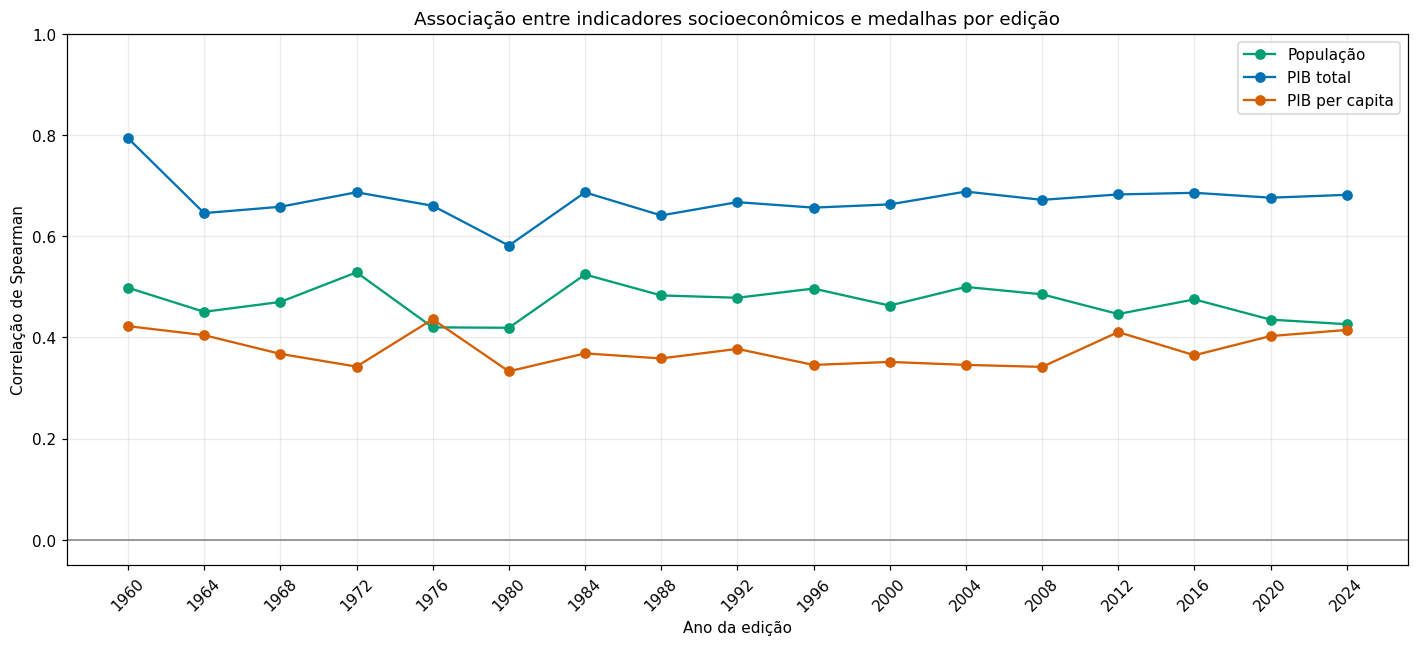

In [25]:
cores_q7 = {'População': '#009E73', 'PIB total': '#0072B2', 'PIB per capita': '#D55E00'}
principal_q7 = correlacoes_q7[correlacoes_q7['amostra'] == 'Participantes com dados']
fig, eixo = plt.subplots(figsize=(13, 6))
for nome, grupo in principal_q7.groupby('indicador', sort=False):
    eixo.plot(grupo['year'], grupo['spearman'], marker='o', label=nome, color=cores_q7[nome])
eixo.set(title='Associação entre indicadores socioeconômicos e medalhas por edição',
         xlabel='Ano da edição', ylabel='Correlação de Spearman', ylim=(-0.05, 1))
eixo.set_xticks(anos_q7)
eixo.tick_params(axis='x', rotation=45)
eixo.axhline(0, color='gray', linewidth=1)
eixo.grid(alpha=0.25)
eixo.legend()
plt.tight_layout()
plt.show()

Os painéis seguintes confrontam a amostra disponível em cada edição com o painel de NOCs constante ao longo do período. A comparação ajuda a distinguir a evolução observada de mudanças na composição da amostra, embora não elimine todos os fatores que variam entre edições.

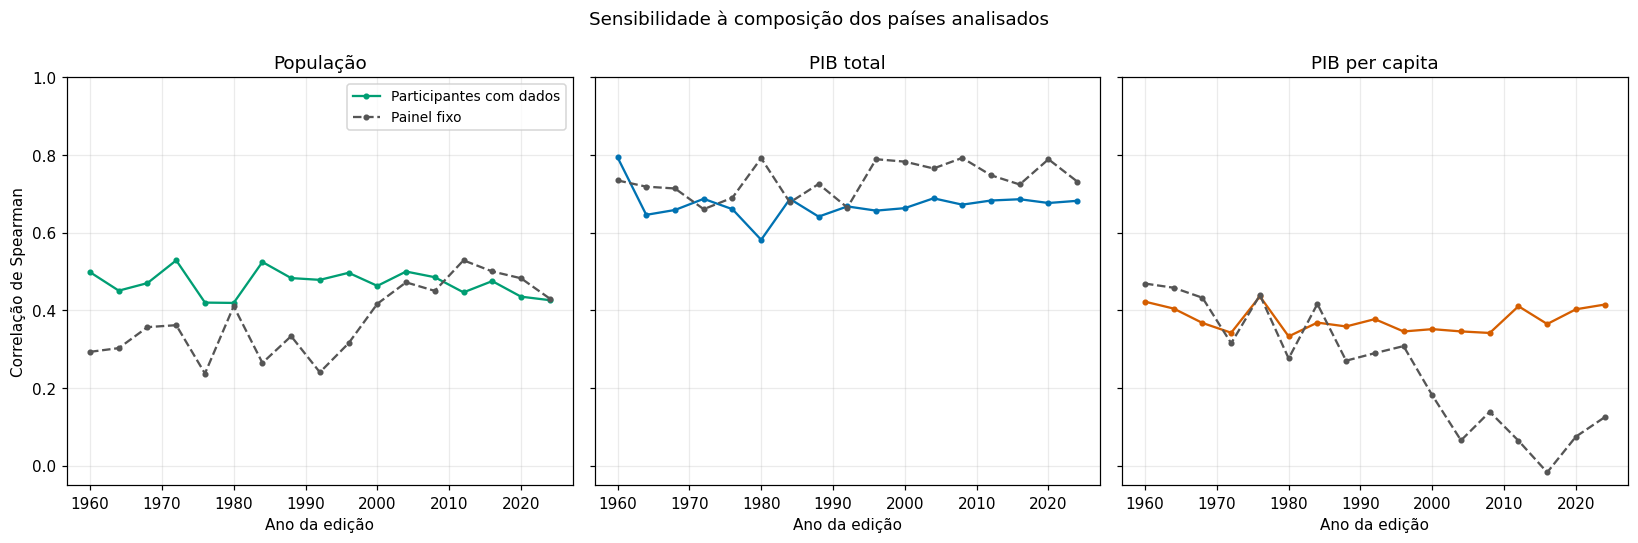

In [26]:
fig, eixos = plt.subplots(1, 3, figsize=(15, 5), sharex=True, sharey=True)
for eixo, nome in zip(eixos, indicadores_q7.values()):
    for amostra, estilo in [('Participantes com dados', '-'), ('Painel fixo', '--')]:
        dados = correlacoes_q7[(correlacoes_q7['indicador'] == nome) &
                              (correlacoes_q7['amostra'] == amostra)]
        eixo.plot(dados['year'], dados['spearman'], linestyle=estilo, marker='o',
                  markersize=3, color=cores_q7[nome] if estilo == '-' else '#555555', label=amostra)
    eixo.set_title(nome)
    eixo.set_xlabel('Ano da edição')
    eixo.set_ylim(-0.05, 1)
    eixo.grid(alpha=0.25)
eixos[0].set_ylabel('Correlação de Spearman')
eixos[0].legend(fontsize=9)
fig.suptitle('Sensibilidade à composição dos países analisados')
plt.tight_layout()
plt.show()

**Análise e Resposta**

A análise abrange **17 edições**, de 1960 a 2024. A amostra comum aos três indicadores cresce de **61 países em 1960** para **191 em 2024**, correspondendo, respectivamente, a aproximadamente **72,6% e 92,7%** dos NOCs identificáveis elegíveis em cada edição. Portanto, a cobertura melhora, mas não é constante nem completa: a ausência de indicadores, inclusive para delegações históricas, deve ser considerada ao interpretar a evolução.

Na amostra disponível de cada edição, **as três associações permanecem positivas ao longo de todo o período**. O PIB total apresenta o maior coeficiente em todas as edições, variando aproximadamente entre **0,58 e 0,79**. A associação com população fica entre **0,42 e 0,53**, enquanto a do PIB per capita varia entre **0,33 e 0,44**. O padrão geral das perguntas anteriores, portanto, não resulta apenas de reunir observações de anos distintos: também aparece quando as edições são examinadas separadamente.

Isso não significa que as relações sejam idênticas. A correlação entre PIB total e medalhas passa de **0,79 em 1960** para **0,58 em 1980** e fica em torno de **0,66 a 0,69 de 1992 a 2024**. Para a população, os valores são aproximadamente **0,50 em 1960** e **0,43 em 2024**. Já o PIB per capita apresenta coeficientes próximos de **0,42** nos dois extremos do período, com oscilações intermediárias. Esses movimentos não formam uma tendência única de aumento ou redução para os três indicadores.

Em 2024, a população e o PIB per capita têm associações de intensidade bastante próxima (**0,43 e 0,41**), ambas inferiores à do PIB total (**0,68**). Essa proximidade também mostra que não seria adequado afirmar que população sempre apresenta associação mais forte do que PIB per capita: em 1976, por exemplo, a ordem se inverte ligeiramente.

A comparação com o **painel fixo de 25 NOCs** acrescenta uma ressalva importante. Nesse grupo, o PIB total continua apresentando a maior associação em todas as edições, com coeficientes entre **0,66 e 0,79**. Porém, as trajetórias dos outros indicadores mudam: a correlação com população passa de cerca de **0,29 em 1960** para **0,43 em 2024**, enquanto a do PIB per capita passa de **0,47 para 0,12**, chegando a aproximadamente **−0,02 em 2016**, valor próximo de zero. Assim, a aparente estabilidade do PIB per capita na amostra mais ampla não se mantém da mesma forma entre os países continuamente observados.

Portanto, **as relações permanecem semelhantes em seu padrão geral, sobretudo na associação mais forte com o PIB total, mas não são invariáveis**. Sua intensidade e evolução dependem do indicador e do conjunto de países analisados. O painel fixo não é uma estimativa mais representativa: é uma verificação restrita a participantes com dados contínuos, sujeita a seleção própria e mudanças territoriais que um código constante não necessariamente captura.

Por fim, os gráficos são descritivos. Não demonstram que variações econômicas causaram mudanças nas medalhas nem testam se diferenças entre coeficientes são estatisticamente significativas. Mudanças no programa esportivo, na composição das delegações e na disponibilidade de dados não são isoladas pelo procedimento. Na próxima pergunta, o foco passa das associações socioeconômicas para os perfis esportivos, distinguindo provas individuais e por equipe.

### 8. Os países que se destacam nas provas individuais também se destacam nas provas por equipe, ou existem perfis distintos de sucesso olímpico?


**Transformação dos Dados**

Esta pergunta utiliza os **Jogos de Verão de 2016**. A escolha decorre da qualidade dos dados: em 2020 e 2024, a base de atletas não registra medalhas em diversas provas por equipe, como duplas e revezamentos. Essas ausências não significam zero medalhas. Em 2016, todas as provas presentes na base possuem registros de medalhistas. A auditoria abaixo torna explícita essa diferença de cobertura.

A classificação é feita por **prova**, e não apenas por esporte. Provas por equipe incluem modalidades coletivas, duplas, revezamentos, equipes de ginástica, conjuntos, barcos com múltiplos atletas e outras conquistas compartilhadas. As demais provas são individuais. As regras textuais abaixo são específicas para os nomes das provas de 2016 e são verificadas contra a multiplicidade dos medalhistas; não devem ser aplicadas automaticamente a outras edições.

Nas provas individuais, cada atleta medalhista conta como uma conquista, preservando eventuais empates entre atletas do mesmo NOC. Nas provas por equipe, os atletas são reduzidos a uma conquista por **NOC × prova × tipo de medalha × equipe**. Assim, uma medalha no futebol tem o mesmo peso de uma medalha individual. Os identificadores de equipe são auditados para evitar dividir uma mesma conquista entre diferentes grafias.

Calculamos o número de medalhas e a **participação de cada NOC no total de medalhas de cada categoria**. Essa normalização considera que as categorias oferecem quantidades diferentes de medalhas. Um país com a mesma participação nos dois grupos tem desempenho proporcionalmente equilibrado, mesmo que tenha mais medalhas individuais em números absolutos.

A comparação de perfis e a correlação utilizam os NOCs que conquistaram pelo menos uma medalha em qualquer categoria; assim, a correlação descreve somente os medalhistas, e não todos os participantes; essa seleção pode alterar o coeficiente. Para destacar diferenças, usamos a distância entre as participações percentuais, em pontos percentuais. Não interpretamos essa diferença como eficiência nem como preferência deliberada por modalidades. Todas as contagens da seção vêm da base de atletas e são comparadas ao quadro agregado, com eventuais divergências apresentadas explicitamente.

In [27]:
# Auditoria de cobertura antes da escolha da edição
linhas_auditoria_q8 = []
for ano in [2016, 2020, 2024]:
    dados = df_atletas[df_atletas['year'] == ano]
    eventos = dados[['sport', 'event']].drop_duplicates()
    premiados = dados[dados['medal'].isin(['Gold', 'Silver', 'Bronze'])]
    eventos_premiados = premiados[['sport', 'event']].drop_duplicates()
    linhas_auditoria_q8.append({'ano': ano, 'provas_na_base': len(eventos),
        'provas_com_medalhistas': len(eventos_premiados),
        'provas_sem_medalhistas': len(eventos) - len(eventos_premiados)})
display(pd.DataFrame(linhas_auditoria_q8))

ANO_Q8 = 2016
atletas_q8 = df_atletas[df_atletas['year'] == ANO_Q8].copy()
classificacao_q8 = atletas_q8[['sport', 'event']].drop_duplicates().copy()
esportes_coletivos_q8 = ['Basketball', 'Football', 'Handball', 'Hockey',
                         'Rugby Sevens', 'Volleyball', 'Water Polo', 'Synchronized Swimming']
# Inclui duplas, revezamentos, equipes, barcos e conjuntos no programa de 2016.
padrao_equipe_q8 = r'Team|Relay|Doubles|Fours|Pairs|Eights|Double Sculls|Quadruple|Synchronized|Group|Two Person|Skiff|Multihull'
classificacao_q8['categoria'] = np.where(
    classificacao_q8['sport'].isin(esportes_coletivos_q8) |
    classificacao_q8['event'].str.contains(padrao_equipe_q8, case=False, regex=True),
    'Por equipe', 'Individual')
medalhistas_q8 = (atletas_q8[atletas_q8['medal'].isin(['Gold', 'Silver', 'Bronze'])]
                  .merge(classificacao_q8, on=['sport', 'event'], validate='many_to_one'))
assert medalhistas_q8['noc'].notna().all()
assert len(classificacao_q8) == medalhistas_q8[['sport', 'event']].drop_duplicates().shape[0]

# Valida a classificação usando a multiplicidade observada por conquista.
multiplicidade_q8 = (medalhistas_q8.groupby(['sport', 'event', 'noc', 'medal'])['id']
                    .nunique().groupby(['sport', 'event']).max().rename('max_atletas_por_conquista'))
classificacao_q8 = classificacao_q8.merge(multiplicidade_q8, on=['sport', 'event'], validate='one_to_one')
assert (classificacao_q8.query('categoria == "Por equipe"')['max_atletas_por_conquista'] > 1).all()
assert (classificacao_q8.query('categoria == "Individual"')['max_atletas_por_conquista'] == 1).all()
display(classificacao_q8.groupby('categoria').size().rename('Número de provas').to_frame())

individuais_q8 = medalhistas_q8.query('categoria == "Individual"').drop_duplicates(
    ['year', 'sport', 'event', 'noc', 'medal', 'id'])
equipes_q8 = medalhistas_q8.query('categoria == "Por equipe"').copy()
assert equipes_q8['team'].notna().all()
# Em 2016, não há duas equipes distintas do mesmo NOC com a mesma medalha na mesma prova.
assert equipes_q8.groupby(['sport', 'event', 'noc', 'medal'])['team'].nunique().max() == 1
equipes_q8 = equipes_q8.drop_duplicates(['year', 'sport', 'event', 'noc', 'medal', 'team'])
conquistas_q8 = pd.concat([individuais_q8, equipes_q8], ignore_index=True)

# Reconcilia os totais por NOC e por metal; não ajusta automaticamente as fontes.
contagem_q8 = conquistas_q8.groupby(['noc', 'medal']).size().unstack(fill_value=0)
quadro_q8 = (df_medalhas[df_medalhas['year'] == ANO_Q8]
             .groupby('noc')[['gold', 'silver', 'bronze']].sum()
             .rename(columns={'gold': 'Gold', 'silver': 'Silver', 'bronze': 'Bronze'}))
diferencas_q8 = contagem_q8.subtract(quadro_q8, fill_value=0)
divergencias_q8 = diferencas_q8[(diferencas_q8 != 0).any(axis=1)]
display(divergencias_q8)

perfis_q8 = conquistas_q8.groupby(['noc', 'categoria']).size().unstack(fill_value=0)
for categoria in ['Individual', 'Por equipe']:
    perfis_q8[f'participacao_{categoria}'] = 100 * perfis_q8[categoria] / perfis_q8[categoria].sum()
perfis_q8['total'] = perfis_q8['Individual'] + perfis_q8['Por equipe']
perfis_q8['diferenca_pp'] = perfis_q8['participacao_Por equipe'] - perfis_q8['participacao_Individual']
nomes_q8 = df_medalhas[df_medalhas['year'] == ANO_Q8].drop_duplicates('noc').set_index('noc')['country']
perfis_q8['country'] = perfis_q8.index.to_series().map(nomes_q8).fillna(perfis_q8.index.to_series())
correlacao_q8 = perfis_q8[['Individual', 'Por equipe']].corr(method='spearman').iloc[0, 1]
display(perfis_q8.sort_values('total', ascending=False).head(15).round(2))

,ano,provas_na_base,provas_com_medalhistas,provas_sem_medalhistas
0,2016,306,306,0
1,2020,333,259,74
2,2024,321,249,72


,Número de provas
categoria,
Individual,226
Por equipe,80


,Bronze,Gold,Silver
noc,,,
KAZ,0,1,0
VEN,1,0,-1


categoria,Individual,Por equipe,participacao_Individual,participacao_Por equipe,total,diferenca_pp,country
noc,,,,,,,
USA,93,28,12.69,11.67,121,-1.02,United States
CHN,54,16,7.37,6.67,70,-0.70,People's Republic of China
GBR,46,21,6.28,8.75,67,2.47,Great Britain
RUS,43,13,5.87,5.42,56,-0.45,Russian Federation
FRA,30,12,4.09,5.00,42,0.91,France
GER,21,21,2.86,8.75,42,5.89,Germany
JPN,33,8,4.50,3.33,41,-1.17,Japan
AUS,13,16,1.77,6.67,29,4.89,Australia
ITA,20,8,2.73,3.33,28,0.60,Italy


Cada ponto representa um NOC medalhista em 2016. A diagonal indica participação igual nas duas categorias: acima dela há maior destaque relativo nas provas por equipe; abaixo, nas individuais. Os eixos têm a mesma escala. Os rótulos destacam os dez maiores totais de medalhas. As maiores diferenças em cada direção aparecem no gráfico seguinte.

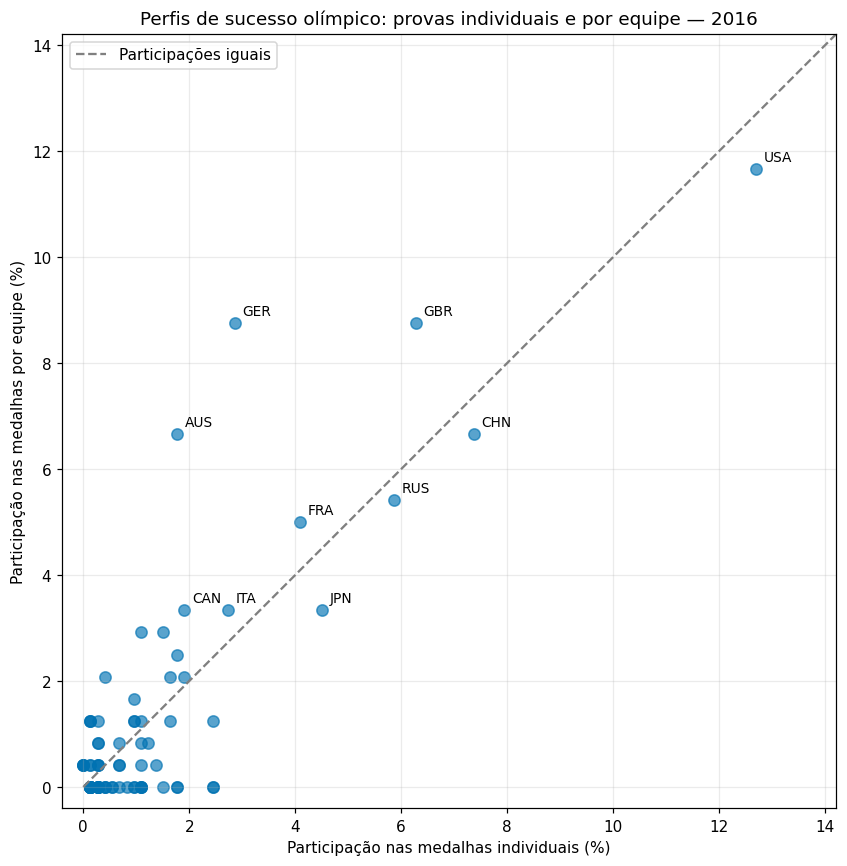

In [28]:
mais_equipe_q8 = perfis_q8[perfis_q8['diferenca_pp'] > 0].nlargest(5, 'diferenca_pp')
mais_individual_q8 = perfis_q8[perfis_q8['diferenca_pp'] < 0].nsmallest(5, 'diferenca_pp')
destaques_q8 = pd.concat([mais_equipe_q8, mais_individual_q8])
rotulos_q8 = set(perfis_q8.nlargest(10, 'total').index)
fig, eixo = plt.subplots(figsize=(9, 8))
eixo.scatter(perfis_q8['participacao_Individual'], perfis_q8['participacao_Por equipe'],
             s=55, alpha=0.65, color='#0072B2')
limite_q8 = perfis_q8[['participacao_Individual', 'participacao_Por equipe']].max().max() * 1.12
eixo.plot([0, limite_q8], [0, limite_q8], '--', color='gray', label='Participações iguais')
for noc in sorted(rotulos_q8):
    r = perfis_q8.loc[noc]
    eixo.annotate(noc, (r['participacao_Individual'], r['participacao_Por equipe']),
                  xytext=(5, 5), textcoords='offset points', fontsize=9)
eixo.set(xlim=(-0.4, limite_q8), ylim=(-0.4, limite_q8),
         xlabel='Participação nas medalhas individuais (%)',
         ylabel='Participação nas medalhas por equipe (%)',
         title='Perfis de sucesso olímpico: provas individuais e por equipe — 2016')
eixo.set_aspect('equal', adjustable='box')
eixo.grid(alpha=0.25)
eixo.legend()
plt.tight_layout()
plt.show()

O segundo gráfico destaca as maiores diferenças entre as participações nas categorias, em pontos percentuais. Valores positivos indicam maior participação nas medalhas por equipe; negativos, nas individuais. São diferenças de participação mundial, e não a porcentagem das medalhas do próprio país que veio de cada categoria.

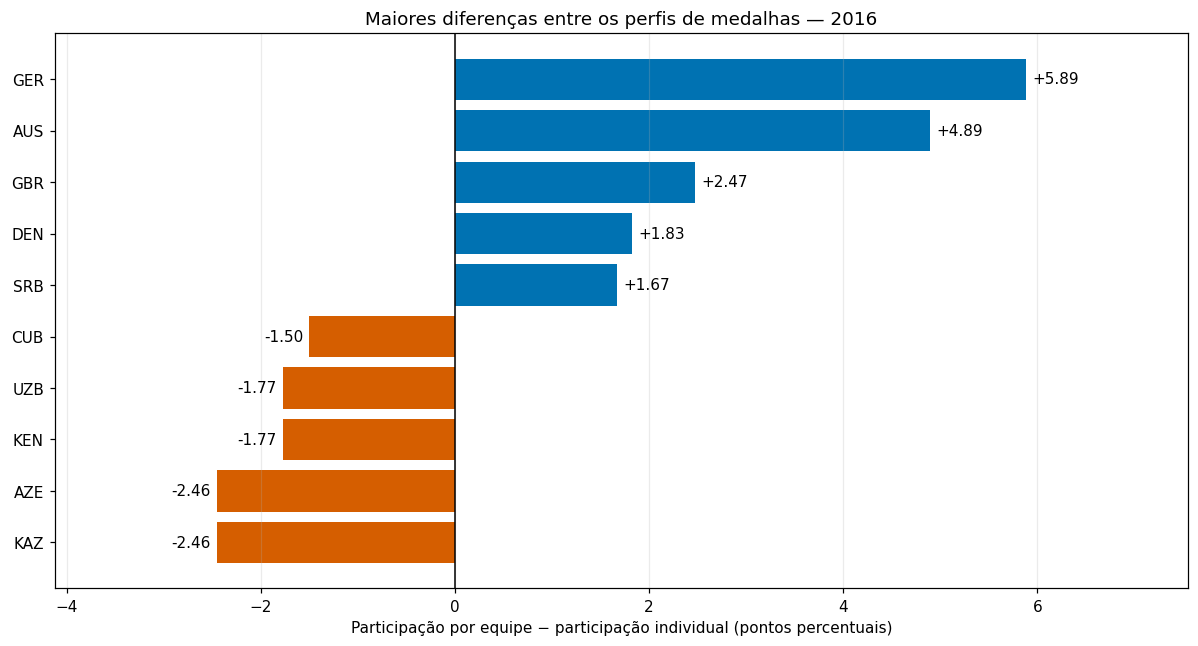

Spearman excluindo NOCs com divergência entre fontes: 0.513


categoria,country,Individual,Por equipe,participacao_Individual,participacao_Por equipe,diferenca_pp
noc,,,,,,
GER,Germany,21,21,2.86,8.75,5.89
AUS,Australia,13,16,1.77,6.67,4.89
GBR,Great Britain,46,21,6.28,8.75,2.47
DEN,Denmark,8,7,1.09,2.92,1.83
SRB,Serbia,3,5,0.41,2.08,1.67
AZE,Azerbaijan,18,0,2.46,0.00,-2.46
KAZ,Kazakhstan,18,0,2.46,0.00,-2.46
KEN,Kenya,13,0,1.77,0.00,-1.77
UZB,Uzbekistan,13,0,1.77,0.00,-1.77


In [29]:
grafico_q8 = destaques_q8.sort_values('diferenca_pp')
fig, eixo = plt.subplots(figsize=(11, 6))
barras = eixo.barh(grafico_q8.index, grafico_q8['diferenca_pp'],
    color=['#0072B2' if v > 0 else '#D55E00' for v in grafico_q8['diferenca_pp']])
eixo.bar_label(barras, fmt='%+.2f', padding=4)
eixo.axvline(0, color='black', linewidth=1)
eixo.margins(x=0.2)
eixo.set(title='Maiores diferenças entre os perfis de medalhas — 2016',
         xlabel='Participação por equipe − participação individual (pontos percentuais)')
eixo.grid(axis='x', alpha=0.25)
plt.tight_layout()
plt.show()
# Verifica se a divergência do quadro agregado afeta a associação geral.
sem_divergencias_q8 = perfis_q8.drop(index=divergencias_q8.index, errors='ignore')
print('Spearman excluindo NOCs com divergência entre fontes:',
      round(sem_divergencias_q8[['Individual', 'Por equipe']].corr(method='spearman').iloc[0, 1], 3))
display(destaques_q8[['country', 'Individual', 'Por equipe',
                    'participacao_Individual', 'participacao_Por equipe', 'diferenca_pp']].round(2))

**Análise e Resposta**

A auditoria confirma a necessidade de um recorte específico: em **2016, as 306 provas presentes na base têm registros de medalhistas**; em 2020, **74 das 333 provas** não têm esses registros; em 2024, o mesmo ocorre em **74 das 323 provas**. Esses números descrevem a cobertura dos arquivos utilizados, não o tamanho oficial dos programas. Assim, utilizar as edições mais recentes sem complementar a fonte subestimaria especialmente as conquistas por equipe.

Para 2016, a classificação identifica **226 provas individuais e 80 por equipe**. Depois de contar cada conquista coletiva uma única vez, obtemos **733 medalhas individuais e 240 por equipe**, totalizando **973 conquistas distribuídas entre 86 NOCs medalhistas**. Há mais medalhas individuais disponíveis; por isso, as participações dentro de cada categoria são mais adequadas para comparar os perfis do que uma comparação direta das contagens.

A reconciliação com o quadro agregado revela diferenças que precisam permanecer visíveis: a base de atletas contém **um ouro a mais para o Cazaquistão**; para a Venezuela, há **um bronze a mais e uma prata a menos**, sem alteração do total. O quadro agregado soma **972 medalhas**, contra 973 reconstruídas. Não corrigimos automaticamente esses registros porque as fontes, sozinhas, não esclarecem a origem das divergências. Todos os números desta seção seguem a base de atletas, e os casos identificados devem ser considerados uma limitação.

Existe uma correspondência entre o destaque nas duas categorias, mas ela é incompleta. A correlação de Spearman entre as contagens individuais e por equipe, calculada somente entre os NOCs medalhistas, é de aproximadamente **0,49**. Os Estados Unidos, por exemplo, lideram ambas, com **93 medalhas individuais e 28 por equipe**, representando aproximadamente **12,69% e 11,67%** das respectivas categorias. China e Grã-Bretanha também aparecem entre os maiores totais nas duas, embora com proporções diferentes.

Ao mesmo tempo, **há perfis distintos de sucesso**. A Alemanha conquistou **21 medalhas em cada categoria**, mas isso corresponde a **2,86% das medalhas individuais e 8,75% das medalhas por equipe**: um destaque relativo muito maior nas provas coletivas, com diferença de **5,89 pontos percentuais**. A Austrália segue um padrão semelhante, com **13 individuais e 16 por equipe**, equivalentes a **1,77% e 6,67%**, diferença de **4,89 pontos percentuais**. Grã-Bretanha, Dinamarca e Sérvia também aparecem entre os maiores desvios em favor das provas por equipe.

Na direção oposta, Azerbaijão e Cazaquistão registram **18 medalhas individuais e nenhuma por equipe** nesta fonte; o total do Cazaquistão está sujeito à divergência descrita acima. Quênia e Uzbequistão têm **13 individuais cada**, também sem conquistas por equipe, e Cuba tem **11**. Esses casos mostram que um país pode alcançar um total expressivo de medalhas com um perfil concentrado nas provas individuais. Entre os 86 NOCs medalhistas, **42 conquistaram medalhas somente em provas individuais, quatro somente em provas por equipe e 40 nas duas categorias**. Os quatro com medalhas apenas por equipe são Áustria, Estônia, Fiji e Nigéria, cada um com uma conquista.

Portanto, **os países que se destacam nas provas individuais não necessariamente apresentam o mesmo destaque nas provas por equipe**. Algumas potências acumulam resultados elevados nas duas categorias, enquanto outros países apresentam perfis mais concentrados. A associação positiva sugere uma hierarquia parcialmente compartilhada, mas os desvios mostram que separar o tipo de prova acrescenta informação que o total de medalhas esconde.

Esses resultados descrevem somente **2016** e não demonstram uma especialização permanente ou intencional. A classificação reúne duplas, revezamentos e grandes equipes na mesma categoria; a participação nas medalhas não controla a quantidade de atletas ou provas disputadas por cada país. Além disso, zero medalhas em uma categoria não significa ausência de participação. As diferenças entre fontes e os empates nos rankings limitam a precisão de comparações muito próximas. A verificação sem os NOCs com divergências, apresentada acima, permite avaliar a associação geral sem esses casos, mas não substitui a reconciliação futura com uma fonte completa por prova.

## Conclusão

Este trabalho investigou a distribuição das medalhas olímpicas, suas associações com características socioeconômicas e as diferenças entre conquistas individuais e por equipe. A combinação de participantes, quadros de medalhas e indicadores do Banco Mundial permitiu incluir delegações sem medalhas e comparar perspectivas que um ranking absoluto não revela.

O primeiro resultado é a **persistência da concentração das conquistas**. Embora a participação tenha aumentado ao longo do recorte histórico, muitas delegações continuam sem medalhas. Em 2024, 92 das 206 delegações identificáveis da base conquistaram alguma medalha, e as dez de maior total concentraram aproximadamente 55,8% das conquistas. A mediana igual a zero e a distância em relação à média mostram que o resultado típico difere bastante daquele alcançado pelas maiores potências esportivas.

O segundo resultado é a **associação positiva entre tamanho econômico e desempenho**, mais forte para PIB total do que para PIB per capita na amostra comum. População também se associa positivamente ao número de medalhas, mas nenhum desses indicadores determina isoladamente o resultado. A análise por edição confirma a predominância da associação com PIB total, enquanto a comparação com um painel fixo evidencia que a evolução das outras relações depende da composição dos países observados. Assim, os resultados gerais não devem ser interpretados como relações invariáveis ao longo do tempo.

A comparação de 2024 entre países próximos em população e PIB per capita mostrou diferenças expressivas de desempenho. Esses desvios reforçam que os dois indicadores não resumem as condições esportivas de uma delegação. A referência utilizada é descritiva e sensível à escolha dos vizinhos; seus resultados não constituem um ranking de eficiência nem estimativas das medalhas que um país deveria conquistar.

Por fim, a análise de 2016 mostrou que **o sucesso nas provas individuais e por equipe é parcialmente compartilhado, mas apresenta perfis distintos**. Algumas delegações acumulam grandes totais nas duas categorias; outras têm participação proporcionalmente maior em uma delas. A Alemanha, por exemplo, conquistou 21 medalhas em cada categoria, mas essas conquistas representaram parcelas muito diferentes dos respectivos totais. A classificação por prova e a contagem única de cada conquista coletiva foram essenciais para evitar comparações distorcidas pelo número de atletas medalhistas.

As conclusões estão sujeitas à cobertura e à consistência das fontes. A correspondência entre códigos históricos e atuais é limitada; o recorte histórico inclui 1906 e uma categoria agregada de equipes mistas; indicadores ausentes alteram as amostras; e a base de atletas apresenta lacunas e divergências documentadas. A preservação das somas do quadro agregado comprova a integridade da junção, mas não garante que a própria fonte esteja completa ou atualizada. Nas análises socioeconômicas, correlações não isolam fatores simultâneos nem demonstram causalidade; na comparação esportiva, o recorte de 2016 não permite afirmar especializações permanentes.

Diante disso, recomendamos interpretar o desempenho com medidas complementares, explicitar o universo de comparação e auditar as fontes antes de construir rankings. Como continuidade, seria útil obter resultados completos por prova para edições recentes e incorporar tamanho das delegações, participação por modalidade e indicadores de estrutura esportiva. O trabalho sustenta que o total de medalhas contém informação relevante, mas sua interpretação depende do contexto econômico, histórico e esportivo em que as conquistas ocorrem.
